# Visualising results

Notebook purpose:
- Load DiD analysis outputs from R into Python
- Plot main results figures
- Inspect relevant nuances

#### 1. Set-up

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
from matplotlib.path import Path
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker

In [2]:
plt.style.use("default")
#mpl.rcParams.update(mpl.rcParamsDefault)

In [3]:
from ipcei_spillovers.io import data_path, results_path, load_df, save_df, save_fig

from ipcei_spillovers.plotting import (
    COLORS,
    style_ax
)

In [4]:
# ============================================================
# Load data
# ============================================================

firm_master_ipcei = load_df(
    "interim", "combined", "firm_master_ipcei_corrected_extended_jan26.csv",
    low_memory=False
)

partnership_master = load_df(
    "interim", "combined", "partnership_master_ipcei_jan26.csv",
    low_memory=False
)

# All ATT results — main, channels, spillovers combined
att_summary = load_df(
    "processed", "r_output", "att_summary_all.csv", low_memory=False
)

# Reference ATTs (total collabs, primary spec only)
reference_atts = load_df(
    "processed", "r_output", "reference_atts.csv", low_memory=False
)

# Event study dynamic ATTs — all outcomes combined
event_study = load_df(
    "processed", "r_output", "event_study_all.csv", low_memory=False
)

# Matched panels for trajectory plots
battery_cs  = load_df(
    "processed", "combined", "battery_spec2_cs_ready.csv", low_memory=False
)
hydrogen_cs = load_df(
    "processed", "combined", "hydrogen_spec2_cs_ready.csv", low_memory=False
)

print(f"firm_master_ipcei: {firm_master_ipcei.shape}")
print(f"att_summary:       {att_summary.shape}")
print(f"reference_atts:    {reference_atts.shape}")
print(f"event_study:       {event_study.shape}")
print(f"battery_cs:        {battery_cs.shape}")
print(f"hydrogen_cs:       {hydrogen_cs.shape}")

# Quick check on available event study labels
print(f"\nEvent study labels:\n{event_study['label'].unique()}")

# Quick check on att_summary outcomes
print(f"\nATT summary outcomes:\n{att_summary['Outcome'].unique()}")

firm_master_ipcei: (239782, 184)
att_summary:       (20, 11)
reference_atts:    (2, 11)
event_study:       (187, 6)
battery_cs:        (16128, 25)
hydrogen_cs:       (25128, 25)

Event study labels:
['Battery — total collabs' 'Hydrogen — total collabs'
 'Battery — technology-focused collaborations'
 'Hydrogen — technology-focused collaborations'
 'Battery — cross-border EU collaborations'
 'Hydrogen — cross-border EU collaborations'
 'Battery — cross-sector collaborations'
 'Hydrogen — cross-sector collaborations'
 'Battery — non-EU collaborations (placebo)'
 'Hydrogen — non-EU collaborations (placebo)'
 'Battery — within-sector collaborations (placebo)'
 'Hydrogen — within-sector collaborations (placebo)']

ATT summary outcomes:
['Total collabs' 'Technology-focused collaborations'
 'Cross-border EU collaborations' 'Cross-sector collaborations'
 'Non-EU collaborations' 'Domestic EU collaborations'
 'Within-sector collaborations']


In [5]:
partnership_master["post_date"] = pd.to_datetime(
    partnership_master["post_date"], errors="coerce"
)

#### 2. Main figures

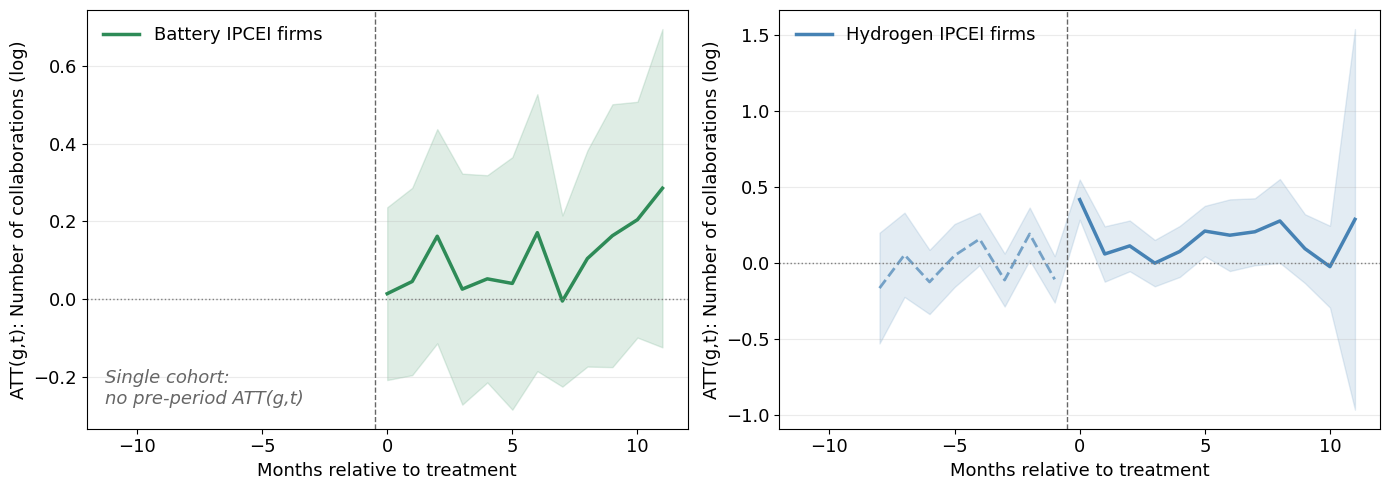

In [9]:
# ============================================================
# Main event study — total collaborations
# ============================================================

def plot_main_event_study(event_study):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    specs = [
        ("Battery — total collabs",  "Battery IPCEI firms",  COLORS["two"][1]),
        ("Hydrogen — total collabs", "Hydrogen IPCEI firms", COLORS["two"][0]),
    ]

    for ax, (label, title, color) in zip(axes, specs):
        df = event_study[event_study["label"] == label].copy()

        if df.empty:
            print(f"WARNING: no rows found for label '{label}'")
            ax.set_title(f"{title} — no data", fontsize=13)
            continue

        df = df[(df["e"] >= -12) & (df["e"] <= 12)]
        pre  = df[df["e"] < 0]
        post = df[df["e"] >= 0]

        ax.fill_between(df["e"], df["cil"], df["ciu"],
                        color=color, alpha=0.15)

        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, linewidth=2,
                    linestyle="--", alpha=0.7)
        ax.plot(post["e"], post["att"], color=color, linewidth=2.5,
                label=title)

        ax.axhline(0,    linestyle=":",  color="grey",    linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)
        ax.set_xlim(-12, 12)

        # Note for Battery (no pre-period)
        if pre.empty:
            ax.text(0.03, 0.05,
                    "Single cohort:\nno pre-period ATT(g,t)",
                    transform=ax.transAxes,
                    fontsize=13, color="#666666", va="bottom", ha="left",
                    style="italic")

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t): Number of collaborations (log)", fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.tick_params(axis="both", labelsize=13)
        ax.legend(frameon=False, fontsize=13)
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", "collaborations_total_event_study")
    plt.show()

plot_main_event_study(event_study)

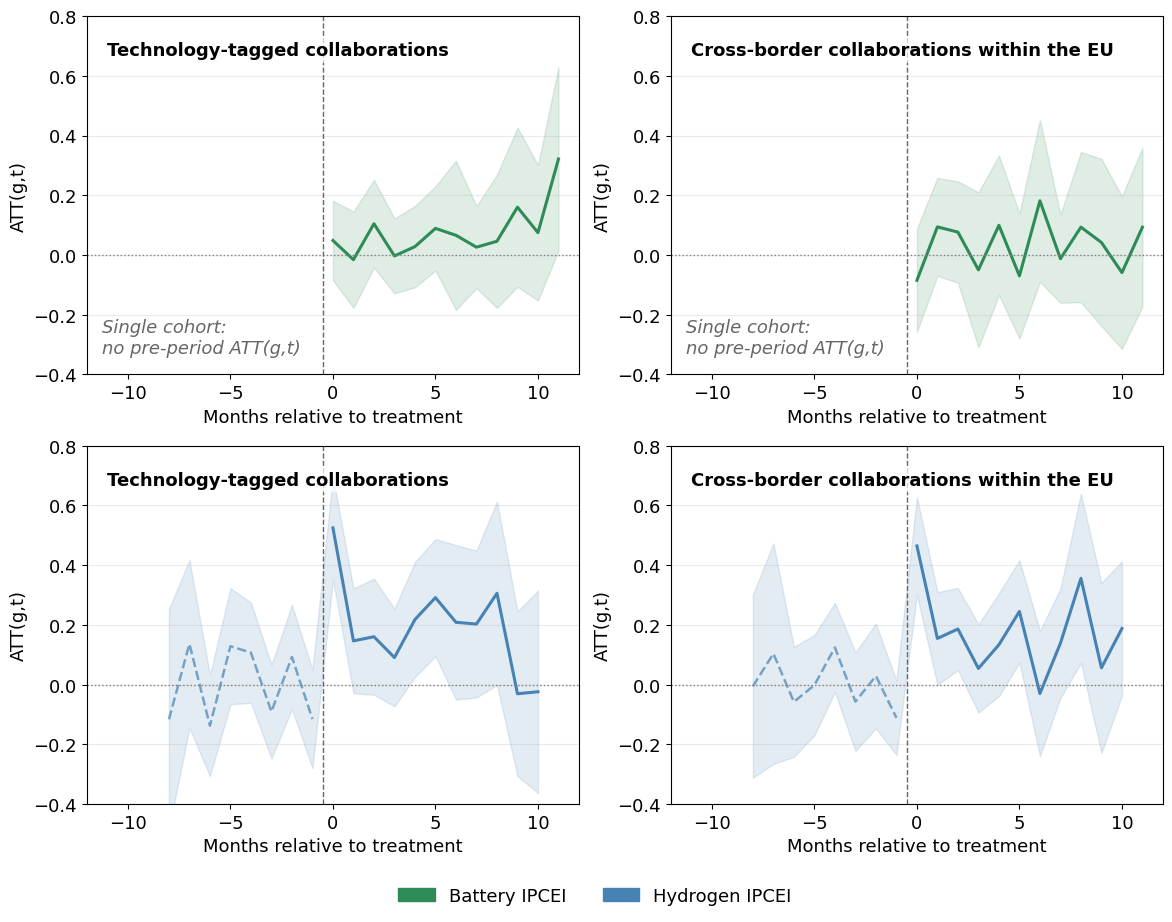

In [6]:
# ============================================================
# Channel decomposition event studies
# ============================================================

def plot_channel_event_studies(event_study):
    channel_specs = [
    ("Battery — technology-focused collaborations",   "Technology-tagged collaborations",          COLORS["two"][1]),
    ("Battery — cross-border EU collaborations",      "Cross-border collaborations within the EU",  COLORS["two"][1]),
    ("Hydrogen — technology-focused collaborations",  "Technology-tagged collaborations",          COLORS["two"][0]),
    ("Hydrogen — cross-border EU collaborations",     "Cross-border collaborations within the EU",  COLORS["two"][0]),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=False)

    x_min, x_max = -12, 12

    for ax, (label, panel_label, color) in zip(axes.flat, channel_specs):
        df = event_study[event_study["label"] == label].copy()
        df = df[(df["e"] >= x_min) & (df["e"] <= x_max)]

        pre  = df[df["e"] < 0]
        post = df[df["e"] >= 0]

        ax.fill_between(df["e"], df["cil"], df["ciu"],
                        color=color, alpha=0.15)

        if not pre.empty:
            ax.plot(pre["e"], pre["att"], color=color, linewidth=1.8,
                    linestyle="--", alpha=0.7)
        ax.plot(post["e"], post["att"], color=color, linewidth=2.2)

        ax.axhline(0,    linestyle=":",  color="grey",    linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(-0.4, 0.8)
        ax.set_yticks(np.arange(-0.4, 0.81, 0.2))
        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        # Within-panel label
        ax.text(0.04, 0.93, panel_label,
                transform=ax.transAxes,
                fontsize=13, fontweight="bold", va="top", ha="left",
                bbox=dict(boxstyle="round,pad=0.2", fc="white",
                          alpha=0.7, ec="none"))

        # Note for single-cohort Battery panels
        if pre.empty:
            ax.text(0.03, 0.05,
                    "Single cohort:\nno pre-period ATT(g,t)",
                    transform=ax.transAxes,
                    fontsize=13, color="#666666", va="bottom", ha="left",
                    style="italic")

        style_ax(ax)


    # Shared legend — Battery and Hydrogen
    battery_patch  = mpatches.Patch(color=COLORS["two"][1],
                                    label="Battery IPCEI")
    hydrogen_patch = mpatches.Patch(color=COLORS["two"][0],
                                    label="Hydrogen IPCEI")
    fig.legend(handles=[battery_patch, hydrogen_patch],
               loc="lower center",
               ncol=2,
               frameon=False,
               fontsize=13,
               bbox_to_anchor=(0.5, -0.03))

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.1)  # make room for legend

    save_fig(fig, "results_main", "collaborations_channels_event_study")
    plt.show()

plot_channel_event_studies(event_study)

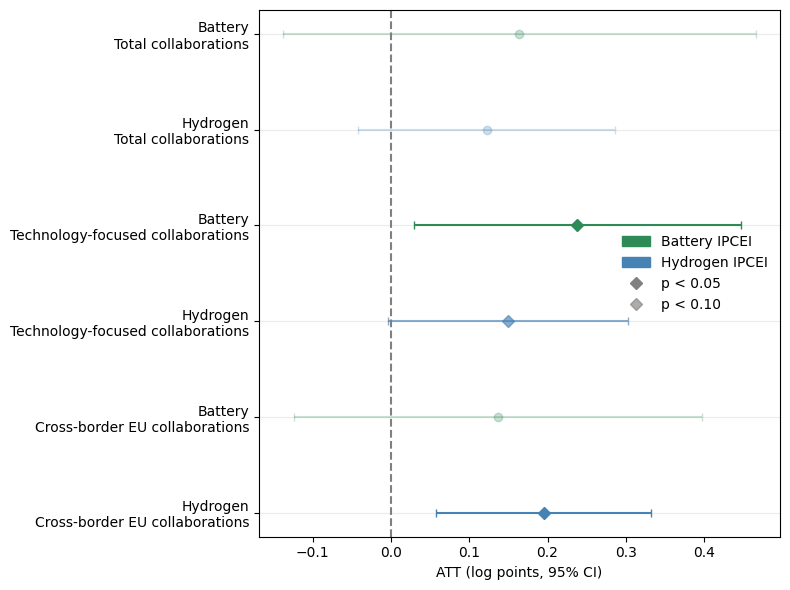

In [9]:
# ============================================================
# ATT coefficient plot
# ============================================================

def plot_att_coefficients(att_summary):

    df = att_summary.copy()
    df.columns = [c.strip().title() for c in df.columns]

    # Keep only the outcomes we want
    keep_outcomes = [
        "Total collabs",
        "Technology-focused collaborations",
        "Cross-border EU collaborations",
    ]
    df = df[df["Outcome"].isin(keep_outcomes)]

    # For total collabs keep only primary spec
    df = df[~((df["Outcome"] == "Total collabs") &
              (df["Type"] != "Primary"))]

    # Rename for display
    df["Outcome"] = df["Outcome"].replace({
        "Total collabs": "Total collaborations",
    })

    # Confidence intervals and significance
    df["Ci_Lo"] = df["Att"] - 1.96 * df["Se"]
    df["Ci_Hi"] = df["Att"] + 1.96 * df["Se"]
    df["Sig_05"] = df["P_Value"] < 0.05
    df["Sig_10"] = (df["P_Value"] >= 0.05) & (df["P_Value"] < 0.10)

    # Order outcomes bottom to top
    outcome_order = [
        "Cross-border EU collaborations",
        "Technology-focused collaborations",
        "Total collaborations",
    ]
    df["Outcome"] = pd.Categorical(
        df["Outcome"], categories=outcome_order, ordered=True
    )
    df = df.sort_values(["Outcome", "Technology"], ascending=[True, False])
    df["Y_Label"] = df["Technology"].astype(str) + "\n" + \
                    df["Outcome"].astype(str)

    fig, ax = plt.subplots(figsize=(8, 6))

    for _, row in df.iterrows():
        color  = COLORS["two"][1] if row["Technology"] == "Battery" \
                 else COLORS["two"][0]

        if row["Sig_05"]:
            alpha  = 1.0
            marker = "D"
        elif row["Sig_10"]:
            alpha  = 0.65
            marker = "D"
        else:
            alpha  = 0.25
            marker = "o"

        ax.errorbar(
            row["Att"], row["Y_Label"],
            xerr=[[row["Att"] - row["Ci_Lo"]], [row["Ci_Hi"] - row["Att"]]],
            fmt=marker, color=color, alpha=alpha,
            capsize=3, linewidth=1.5, markersize=6
        )

    ax.axvline(0, linestyle="--", color="grey")
    ax.set_xlabel("ATT (log points, 95% CI)")

    patches = [
        mpatches.Patch(color=COLORS["two"][1], label="Battery IPCEI"),
        mpatches.Patch(color=COLORS["two"][0], label="Hydrogen IPCEI"),
        plt.Line2D([0], [0], marker="D", color="grey", linestyle="None",
                   markersize=6, alpha=1.0,  label="p < 0.05"),
        plt.Line2D([0], [0], marker="D", color="grey", linestyle="None",
                   markersize=6, alpha=0.65, label="p < 0.10"),
        #plt.Line2D([0], [0], marker="o", color="grey", linestyle="None",
        #           markersize=6, alpha=0.40, label="p ≥ 0.10"),
    ]

    ax.legend(handles=patches, frameon=False, loc="center right")
    style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", "collaborations_att_coefficients")
    plt.show()

plot_att_coefficients(att_summary)

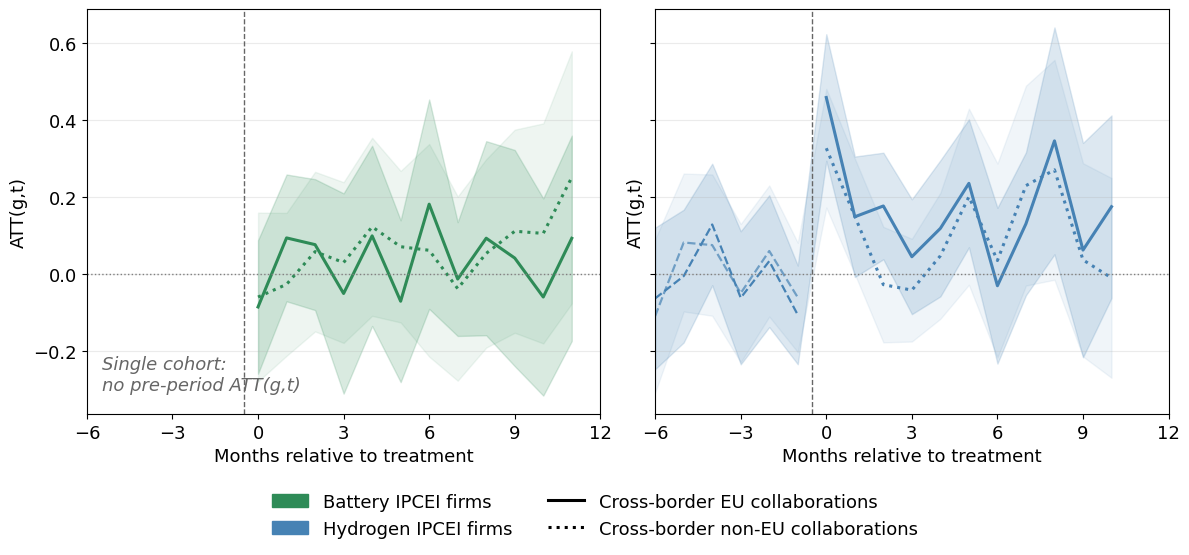

In [6]:
# ============================================================
# EU collaboration event studies
# ============================================================

def plot_eu_event_overlay(event_study):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    specs = [
        ("Battery",  "Battery — cross-border EU collaborations",  "Battery — non-EU collaborations (placebo)"),
        ("Hydrogen", "Hydrogen — cross-border EU collaborations", "Hydrogen — non-EU collaborations (placebo)"),
    ]

    for ax, (tech, eu_label, non_label) in zip(axes, specs):

        eu = event_study[event_study["label"] == eu_label].copy()
        non = event_study[event_study["label"] == non_label].copy()

        eu = eu[(eu["e"] >= -6) & (eu["e"] <= 12)]
        non = non[(non["e"] >= -6) & (non["e"] <= 12)]

        base_color = COLORS["two"][1] if tech == "Battery" else COLORS["two"][0]

        # --- EU collaborations ---
        ax.fill_between(eu["e"], eu["cil"], eu["ciu"],
                        color=base_color, alpha=0.18)

        pre = eu[eu["e"] < 0]
        post = eu[eu["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2)

        # --- NON-EU collaborations ---
        ax.fill_between(non["e"], non["cil"], non["ciu"],
                        color=base_color, alpha=0.08)

        pre = non[non["e"] < 0]
        post = non[non["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=base_color,
                    linestyle="--", linewidth=1.6, alpha=0.7)

        ax.plot(post["e"], post["att"],
                color=base_color,
                linewidth=2.2,
                linestyle=":")

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_xlim(-6, 12)
        ax.set_xticks(range(-6, 13, 3))

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        has_pre = (
            (not eu[eu["e"] < 0].empty) or
            (not non[non["e"] < 0].empty)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=13,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)

    # Shared legend — technology colors + line meanings
    battery_patch = mpatches.Patch(
        color=COLORS["two"][1],
        label="Battery IPCEI firms"
    )
    hydrogen_patch = mpatches.Patch(
        color=COLORS["two"][0],
        label="Hydrogen IPCEI firms"
    )

    eu_line = Line2D(
        [0], [0],
        color="black",
        linewidth=2.2,
        linestyle="-",
        label="Cross-border EU collaborations"
    )
    non_eu_line = Line2D(
        [0], [0],
        color="black",
        linewidth=2.2,
        linestyle=":",
        label="Cross-border non-EU collaborations"
    )

    fig.legend(
        handles=[battery_patch, hydrogen_patch, eu_line, non_eu_line],
        loc="lower center",
        ncol=2,
        frameon=False,
        fontsize=13,
        bbox_to_anchor=(0.5, -0.12)
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16)

    save_fig(fig, "results_main", "eu_event_overlay")
    plt.show()

plot_eu_event_overlay(event_study)

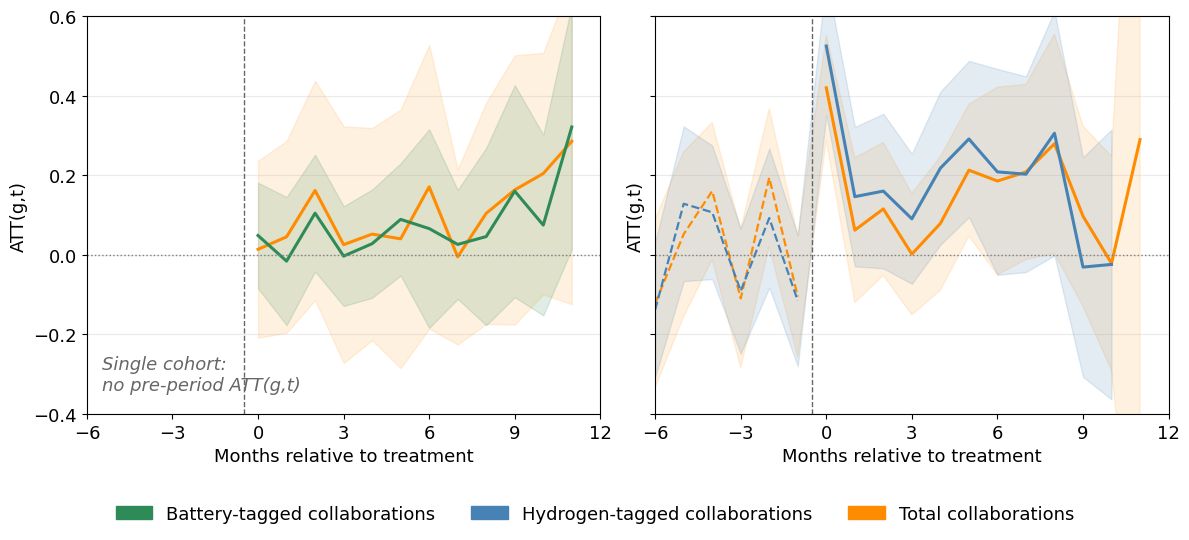

In [12]:
# ============================================================
# Technology channel event studies
# ============================================================

def plot_tech_event_overlay(event_study):

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

    specs = [
        ("Battery",  "Battery — total collabs",   "Battery — technology-focused collaborations"),
        ("Hydrogen", "Hydrogen — total collabs",  "Hydrogen — technology-focused collaborations"),
    ]

    for ax, (tech, total_label, tech_label) in zip(axes, specs):

        total = event_study[event_study["label"] == total_label].copy()
        techs = event_study[event_study["label"] == tech_label].copy()

        total = total[(total["e"] >= -6) & (total["e"] <= 12)]
        techs = techs[(techs["e"] >= -6) & (techs["e"] <= 12)]

        # --- TOTAL collaborations ---
        ax.fill_between(total["e"], total["cil"], total["ciu"],
                        color=COLORS["three"][2], alpha=0.12)

        pre = total[total["e"] < 0]
        post = total[total["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=COLORS["three"][2],
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=COLORS["three"][2],
                linewidth=2.2)

        # --- TECH collaborations ---
        color = COLORS["two"][1] if tech == "Battery" else COLORS["two"][0]

        ax.fill_between(techs["e"], techs["cil"], techs["ciu"],
                        color=color, alpha=0.15)

        pre = techs[techs["e"] < 0]
        post = techs[techs["e"] >= 0]

        if not pre.empty:
            ax.plot(pre["e"], pre["att"],
                    color=color,
                    linestyle="--", linewidth=1.6)

        ax.plot(post["e"], post["att"],
                color=color,
                linewidth=2.2)

        ax.axhline(0, linestyle=":", color="grey", linewidth=1)
        ax.axvline(-0.5, linestyle="--", color="#666666", linewidth=1)

        ax.set_ylim(-0.4, 0.6)
        ax.set_xlim(-6, 12)
        ax.set_xticks(range(-6, 13, 3))

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("ATT(g,t)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)

        has_pre = (
            (not total[total["e"] < 0].empty) or
            (not techs[techs["e"] < 0].empty)
        )

        if not has_pre:
            ax.text(
                0.03, 0.05,
                "Single cohort:\nno pre-period ATT(g,t)",
                transform=ax.transAxes,
                fontsize=13,
                color="#666666",
                va="bottom",
                ha="left",
                style="italic"
            )

        style_ax(ax)

    # Shared legend — technology colors + outcome type
    battery_patch = mpatches.Patch(
        color=COLORS["two"][1],
        label="Battery-tagged collaborations"
    )
    hydrogen_patch = mpatches.Patch(
        color=COLORS["two"][0],
        label="Hydrogen-tagged collaborations"
    )
    total_patch = mpatches.Patch(
        color=COLORS["three"][2],
        label="Total collaborations"
    )

    fig.legend(
        handles=[battery_patch, hydrogen_patch, total_patch],
        loc="lower center",
        ncol=3,
        frameon=False,
        fontsize=13,
        bbox_to_anchor=(0.5, -0.09)
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.16)

    save_fig(fig, "results_main", "tech_event_overlay")
    plt.show()

plot_tech_event_overlay(event_study)

#### 3. Annotated trajectories

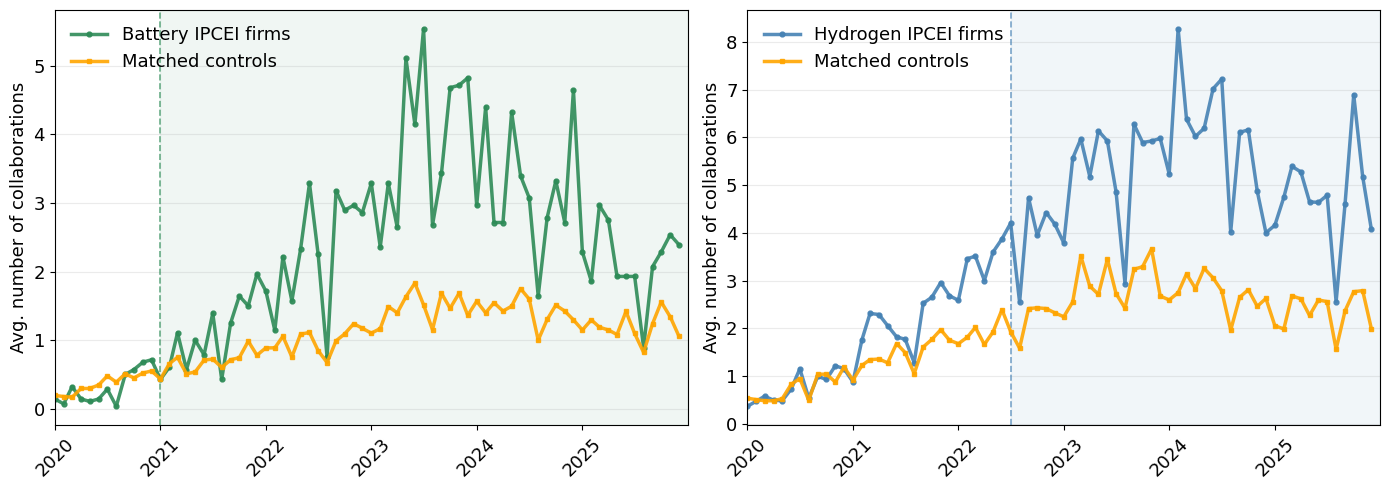

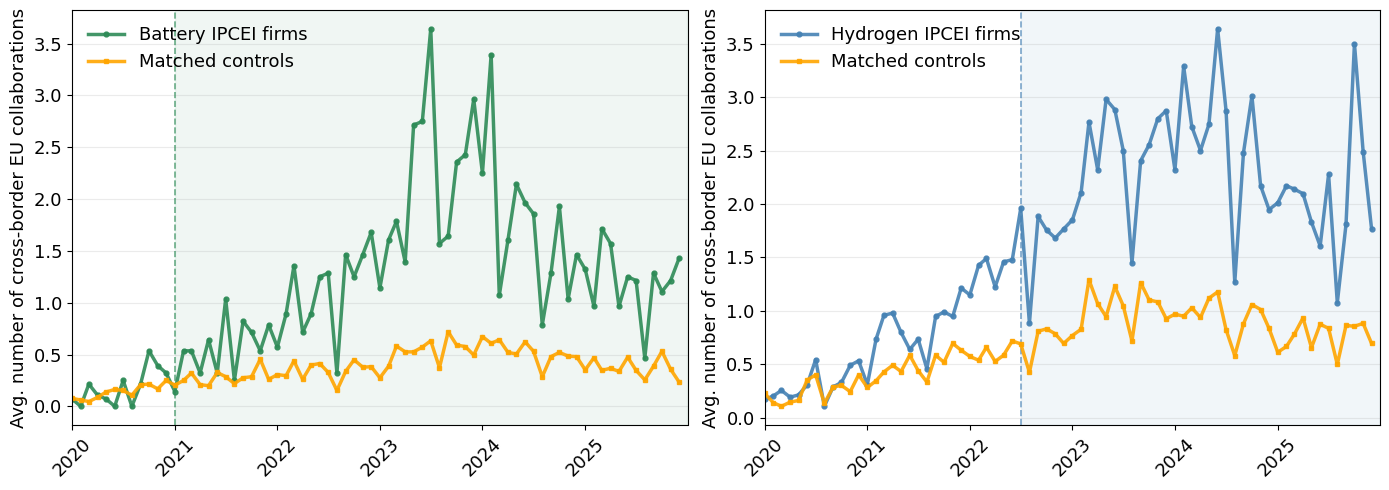

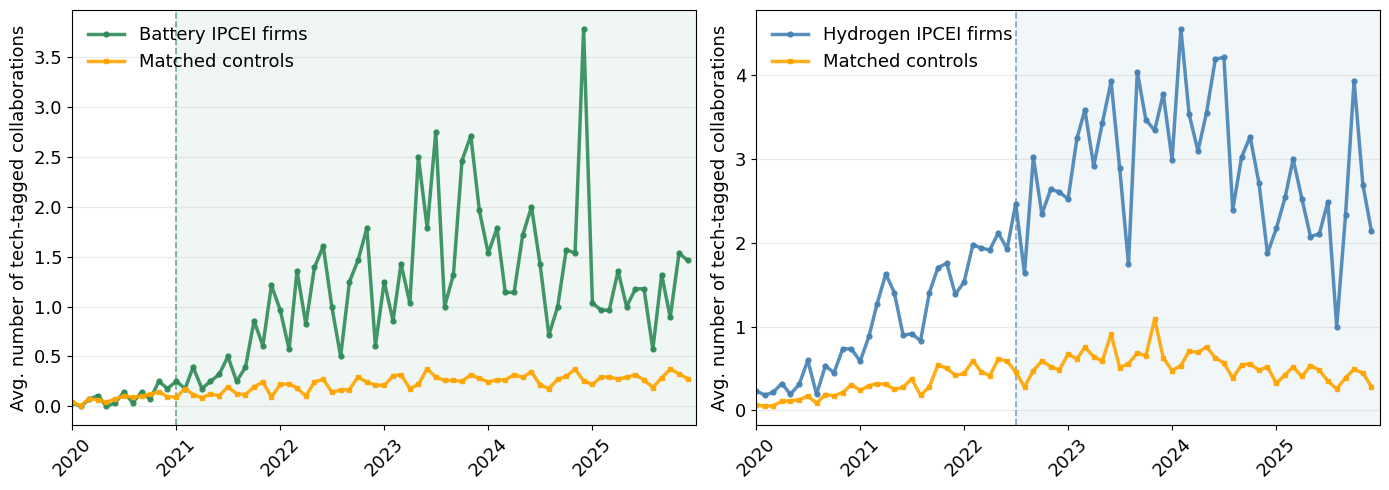

In [7]:
# ============================================================
# Annotated outcome trajectories — channels
# ============================================================

def plot_annotated_trajectories(battery_cs, hydrogen_cs,
                                outcome_col="n_collabs",
                                ylabel="Avg. number of collaborations",
                                figname="collaborations_annotated_trajectories"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    panels = [
        (battery_cs,  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "Hydrogen IPCEI", COLORS["two"][0], "2022-07-01"),
    ]

    for ax, (panel, title, color, treat_start) in zip(axes, panels):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        if outcome_col not in p.columns:
            print(f"WARNING: column '{outcome_col}' not found. Available: {p.columns.tolist()}")
            continue

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[outcome_col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[outcome_col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        ax.set_ylabel(ylabel, fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.legend(frameon=False, loc="upper left", fontsize=13)
        ax.tick_params(axis="x", rotation=45, labelsize=13)
        ax.tick_params(axis="y", labelsize=13)

        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", figname)
    plt.show()

# Total collabs (already working)
plot_annotated_trajectories(battery_cs, hydrogen_cs)

# EU cross-border collabs
plot_annotated_trajectories(
    battery_cs, hydrogen_cs,
    outcome_col="n_collabs_eu_crossborder",
    ylabel="Avg. number of cross-border EU collaborations",
    figname="eu_crossborder_collabs_annotated_trajectories"
)

# Tech-specific collabs
# Battery panel uses n_collabs_battery, Hydrogen uses n_collabs_hydrogen
# These differ per technology so we call separately and combine manually
def plot_tech_trajectories(battery_cs, hydrogen_cs):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    configs = [
        (battery_cs,  "n_collabs_battery",  "Battery IPCEI",  COLORS["two"][1], "2021-01-01"),
        (hydrogen_cs, "n_collabs_hydrogen", "Hydrogen IPCEI", COLORS["two"][0], "2022-07-01"),
    ]

    for ax, (panel, col, title, color, treat_start) in zip(axes, configs):
        p = panel.copy()
        p["month_dt"] = pd.to_datetime(p["month"])

        treated_traj = p[p["is_treated"] == 1].groupby("month_dt")[col].mean()
        control_traj = p[p["is_control"] == 1].groupby("month_dt")[col].mean()

        ax.axvspan(pd.Timestamp(treat_start), pd.Timestamp("2025-12-31"),
                   alpha=0.07, color=color)
        ax.axvline(pd.Timestamp(treat_start), linestyle="--",
                   color=color, linewidth=1.2, alpha=0.7)

        ax.plot(treated_traj.index, treated_traj.values,
                color=color, linewidth=2.5, marker="o",
                markersize=3.5, label=f"{title} firms", alpha=0.9)
        ax.plot(control_traj.index, control_traj.values,
                color="#FFA500", linewidth=2.5, marker="s",
                markersize=3.5, label="Matched controls", alpha=0.9)

        ax.set_xlim(pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31"))
        ax.set_ylabel("Avg. number of tech-tagged collaborations", fontsize=13)
        ax.set_title(title, fontsize=13)
        ax.legend(frameon=False, loc="upper left", fontsize=13)
        ax.tick_params(axis="x", rotation=45, labelsize=13)
        ax.tick_params(axis="y", labelsize=13)
        style_ax(ax)

    plt.tight_layout()
    save_fig(fig, "results_main", "tech_collabs_annotated_trajectories")
    plt.show()

plot_tech_trajectories(battery_cs, hydrogen_cs)

#### 4. Maps and network plots

Battery:
  Positive pairs: 32  |  Negative pairs: 10
  Countries: ['AT', 'BE', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'IE', 'IT', 'LU', 'NL', 'PL', 'SE', 'SI', 'SK']
Hydrogen:
  Positive pairs: 55  |  Negative pairs: 9
  Countries: ['AT', 'BE', 'BG', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IT', 'LT', 'LU', 'LV', 'NL', 'PL', 'PT', 'SE', 'SI', 'SK']


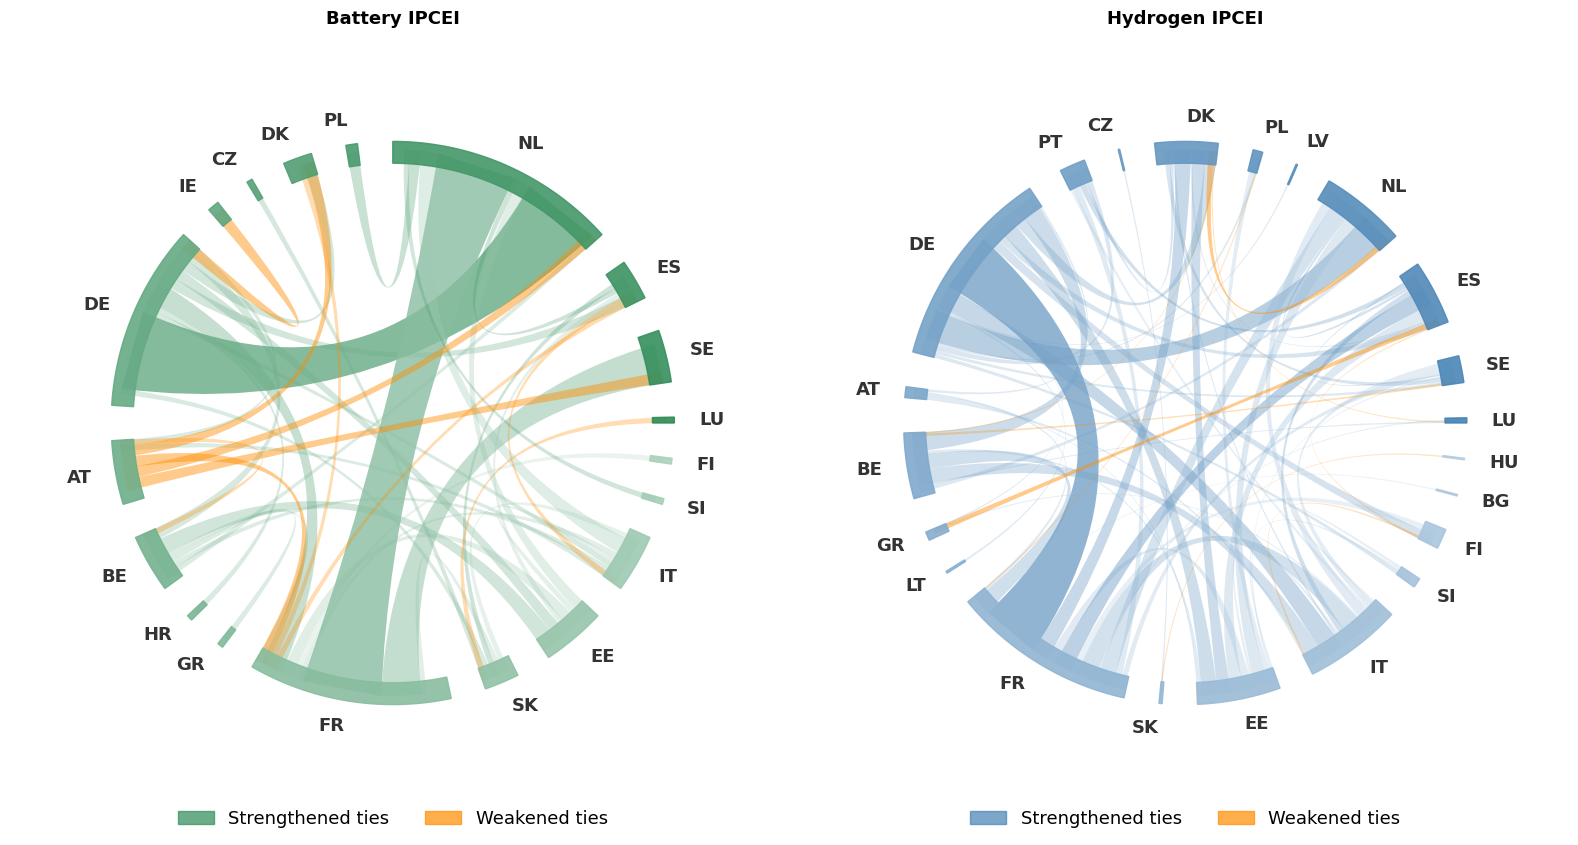

In [26]:
# ============================================================
# Chord diagram — Change in EU cross-border ties
# IPCEI firms × non-IPCEI EU partners only
# ±12 month window, minimum flow threshold (1 vs 3)
# ============================================================

def build_country_pairs(partnership_master, firm_master_ipcei,
                        treated_names, tech_col, treatment_date,
                        eu_codes, end_date=None, min_flow=5):
    """
    Build country-pair flow matrix for treated firms.
    Excludes IPCEI-IPCEI pairs.
    Keeps all pairs above min_flow threshold.
    """
    primary_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["primary_country"].str.strip().str.upper()
    ))

    all_ipcei = set(firm_master_ipcei.loc[
        firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1,
        "Linkedin_name"
    ])

    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
    p = p[p["post_date"] >= pd.Timestamp(treatment_date)]
    if end_date:
        p = p[p["post_date"] < pd.Timestamp(end_date)]

    p = p[p[tech_col] == 1]
    p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

    # Exclude IPCEI-IPCEI pairs
    p = p[~(p["source"].isin(all_ipcei) & p["target"].isin(all_ipcei))]

    p["src_country"] = p["source"].map(primary_map)
    p["tgt_country"] = p["target"].map(primary_map)

    p = p[
        p["src_country"].isin(eu_codes) &
        p["tgt_country"].isin(eu_codes) &
        (p["src_country"] != p["tgt_country"])
    ]

    p["pair"] = p.apply(
        lambda r: tuple(sorted([r["src_country"], r["tgt_country"]])), axis=1
    )

    flows = (
        p.groupby("pair")["collaboration_id"]
         .nunique()
         .reset_index(name="n")
    )
    flows["country_a"] = flows["pair"].apply(lambda x: x[0])
    flows["country_b"] = flows["pair"].apply(lambda x: x[1])

    # Option B — keep all pairs above minimum flow threshold
    flows = flows[flows["n"] >= min_flow]

    top_countries = list(set(
        flows["country_a"].tolist() + flows["country_b"].tolist()
    ))

    return flows, top_countries


def build_country_pairs_delta(partnership_master, firm_master_ipcei,
                               treated_names, tech_col, treatment_date,
                               eu_codes, window_months=12, min_flow=3):
    """
    Compute change in country-pair flows:
    delta = post (0 to +window) minus pre (-window to 0).
    Keeps pairs where absolute delta >= min_flow.
    """
    t          = pd.Timestamp(treatment_date)
    pre_start  = t - pd.DateOffset(months=window_months)
    post_end   = t + pd.DateOffset(months=window_months)

    flows_pre, _ = build_country_pairs(
        partnership_master, firm_master_ipcei,
        treated_names  = treated_names,
        tech_col       = tech_col,
        treatment_date = str(pre_start.date()),
        end_date       = str(t.date()),
        eu_codes       = eu_codes,
        min_flow       = 1   # low threshold for pre — delta filter applied below
    )

    flows_post, _ = build_country_pairs(
        partnership_master, firm_master_ipcei,
        treated_names  = treated_names,
        tech_col       = tech_col,
        treatment_date = str(t.date()),
        end_date       = str(post_end.date()),
        eu_codes       = eu_codes,
        min_flow       = 1   # low threshold for post — delta filter applied below
    )

    delta = flows_pre[["pair", "n"]].rename(columns={"n": "n_pre"}).merge(
        flows_post[["pair", "n"]].rename(columns={"n": "n_post"}),
        on="pair", how="outer"
    ).fillna(0)

    delta["n_delta"]   = delta["n_post"] - delta["n_pre"]
    delta["country_a"] = delta["pair"].apply(lambda x: x[0])
    delta["country_b"] = delta["pair"].apply(lambda x: x[1])

    # Keep only pairs with meaningful absolute change
    delta = delta[delta["n_delta"].abs() >= min_flow]

    top_countries = list(set(
        delta["country_a"].tolist() + delta["country_b"].tolist()
    ))

    delta_pos = delta[delta["n_delta"] >  0].copy().rename(
        columns={"n_delta": "n"})
    delta_neg = delta[delta["n_delta"] <  0].copy()
    delta_neg["n"] = delta_neg["n_delta"].abs()

    print(f"  Positive pairs: {len(delta_pos)}  |  Negative pairs: {len(delta_neg)}")
    print(f"  Countries: {sorted(top_countries)}")

    return delta_pos, delta_neg, top_countries


def draw_chord_delta(ax, flows_pos, flows_neg, countries, color, title):
    n = len(countries)
    if n == 0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes)
        return

    all_flows = pd.concat([
        flows_pos[["country_a", "country_b", "n"]],
        flows_neg[["country_a", "country_b", "n"]]
    ], ignore_index=True)

    totals = {c: 0 for c in countries}
    for _, row in all_flows.iterrows():
        if row["country_a"] in totals: totals[row["country_a"]] += row["n"]
        if row["country_b"] in totals: totals[row["country_b"]] += row["n"]

    grand_total = sum(totals.values()) or 1
    gap = 0.02

    arc_pos = {}
    angle = 0
    for c in countries:
        span = (totals[c] / grand_total) * (1 - gap * n)
        arc_pos[c] = {"start": angle, "end": angle + span}
        angle += span + gap

    for c in arc_pos:
        arc_pos[c]["start"] *= 2 * np.pi
        arc_pos[c]["end"]   *= 2 * np.pi

    base = mcolors.to_rgb(color)
    country_colors = {}
    for i, c in enumerate(countries):
        t = i / max(len(countries) - 1, 1)
        lightened = tuple(base[j] + t * (1 - base[j]) * 0.6 for j in range(3))
        country_colors[c] = lightened

    def draw_chords(flows, chord_color_fn, alpha_fn):
        fill_pos = {c: arc_pos[c]["start"] for c in countries}
        max_n = flows["n"].max() if len(flows) > 0 else 1

        for _, row in flows.iterrows():
            ca, cb, n_flow = row["country_a"], row["country_b"], row["n"]
            if ca not in arc_pos or cb not in arc_pos:
                continue

            span = (n_flow / grand_total) * 2 * np.pi * (1 - gap * n)

            a0 = fill_pos[ca]; a1 = a0 + span
            b0 = fill_pos[cb]; b1 = b0 + span
            fill_pos[ca] += span
            fill_pos[cb] += span

            def pt(angle, r=1):
                return (r * np.cos(angle), r * np.sin(angle))

            verts = [
                pt(a0), (0, 0), pt(b1),
                pt(b0), (0, 0), pt(a1),
                pt(a0)
            ]
            codes = [
                Path.MOVETO, Path.CURVE3, Path.CURVE3,
                Path.LINETO, Path.CURVE3, Path.CURVE3,
                Path.CLOSEPOLY
            ]
            path  = Path(verts, codes)
            patch = mpatches.PathPatch(
                path,
                facecolor = chord_color_fn(ca),
                edgecolor = "none",
                alpha     = alpha_fn(n_flow, max_n)
            )
            ax.add_patch(patch)

    # Positive chords — technology color
    draw_chords(
        flows_pos,
        chord_color_fn = lambda ca: country_colors.get(ca, (0.5, 0.5, 0.5)),
        alpha_fn       = lambda n, mx: 0.2 + 0.6 * (n / mx)
    )

    # Negative chords — orange
    draw_chords(
        flows_neg,
        chord_color_fn = lambda ca: mcolors.to_rgb("darkorange"),
        alpha_fn       = lambda n, mx: 0.15 + 0.3 * (n / mx)
    )

    # Outer arcs and labels
    R_inner, R_outer, R_label = 0.95, 1.03, 1.12

    for c in countries:
        a_start = arc_pos[c]["start"]
        a_end   = arc_pos[c]["end"]
        mid     = (a_start + a_end) / 2

        theta   = np.linspace(a_start, a_end, 50)
        x_outer = R_outer * np.cos(theta)
        y_outer = R_outer * np.sin(theta)
        x_inner = R_inner * np.cos(theta[::-1])
        y_inner = R_inner * np.sin(theta[::-1])

        ax.fill(
            np.concatenate([x_outer, x_inner]),
            np.concatenate([y_outer, y_inner]),
            color=country_colors.get(c, (0.5, 0.5, 0.5)), alpha=0.9
        )

        ha = "left" if np.cos(mid) > 0 else "right"
        ax.text(
            R_label * np.cos(mid),
            R_label * np.sin(mid),
            c, ha=ha, va="center",
            fontsize=13, fontweight="bold", color="#333333"
        )

    ax.set_xlim(-1.4, 1.4)
    ax.set_ylim(-1.4, 1.4)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)

    pos_patch = mpatches.Patch(color=color,        alpha=0.7,
                                label="Strengthened ties")
    neg_patch = mpatches.Patch(color="darkorange",  alpha=0.7,
                                label="Weakened ties")
    ax.legend(handles=[pos_patch, neg_patch],
              loc="lower center", frameon=False,
              fontsize=13, ncol=2,
              bbox_to_anchor=(0.5, -0.05))


# ── EU codes ──────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

battery_treated  = set(battery_cs[battery_cs["is_treated"]  == 1]["Linkedin_name"])
hydrogen_treated = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"])

# ── Build delta flows ─────────────────────────────────────────────────────────
print("Battery:")
battery_pos, battery_neg, battery_countries = build_country_pairs_delta(
    partnership_master, firm_master_ipcei,
    treated_names    = battery_treated,
    tech_col         = "Battery",
    treatment_date   = "2021-01-01",
    eu_codes         = EU_CODES,
    window_months    = 12,
    min_flow         = 1
)

print("Hydrogen:")
hydrogen_pos, hydrogen_neg, hydrogen_countries = build_country_pairs_delta(
    partnership_master, firm_master_ipcei,
    treated_names    = hydrogen_treated,
    tech_col         = "Hydrogen",
    treatment_date   = "2022-07-01",
    eu_codes         = EU_CODES,
    window_months    = 12,
    min_flow         = 3
)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

draw_chord_delta(
    axes[0], battery_pos,  battery_neg,  battery_countries,
    color = COLORS["two"][1],
    title = "Battery IPCEI"
)
draw_chord_delta(
    axes[1], hydrogen_pos, hydrogen_neg, hydrogen_countries,
    color = COLORS["two"][0],
    title = "Hydrogen IPCEI"
)

plt.tight_layout()
save_fig(fig, "results_descriptive", "collaborations_crossborder_chord_delta")
plt.show()

Battery:
  Flows above threshold: 43
  IPCEI countries:   ['AT', 'DE', 'EE', 'FR', 'GR', 'HR', 'IT', 'NL', 'SK']
  Partner countries: ['BE', 'CZ', 'DE', 'DK', 'ES', 'FI', 'FR', 'IE', 'IT', 'LU', 'NL', 'PL', 'SE', 'SI']

Hydrogen:
  Flows above threshold: 81
  IPCEI countries:   ['AT', 'BE', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'IT', 'NL', 'PT', 'SE', 'SK']
  Partner countries: ['AT', 'BE', 'BG', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IT', 'LT', 'LU', 'LV', 'NL', 'PL', 'PT', 'SE', 'SI']
Battery right countries:  14
Hydrogen right countries: 21
Shared figure height:     7.3


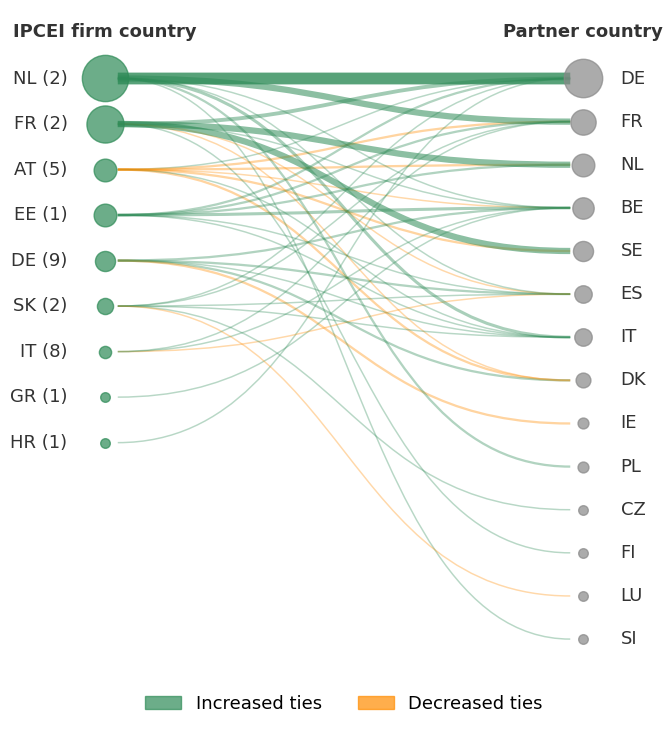

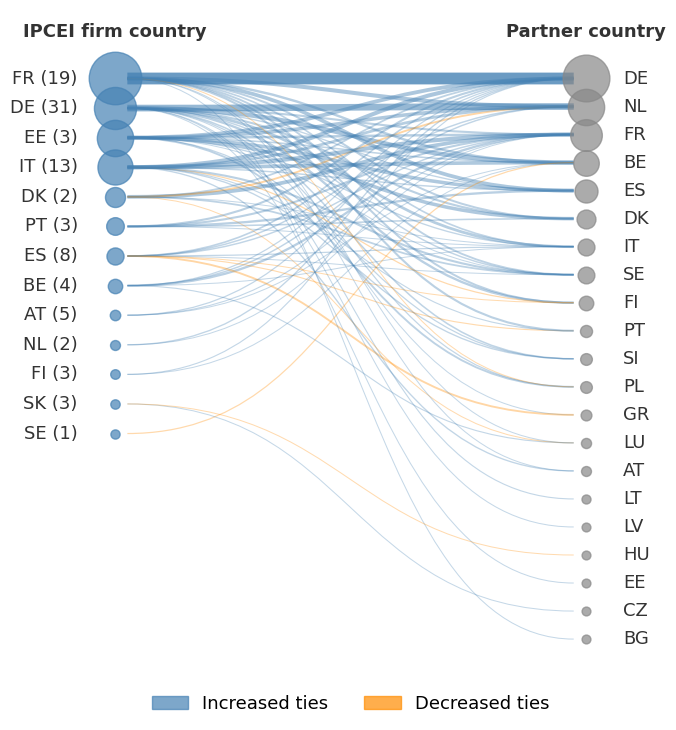

In [9]:
# ============================================================
# Sankey-style bipartite flow chart
# IPCEI country (left) → partner country (right)
# Delta: post minus pre, ±12 months around treatment
# Outer ring on left nodes = number of IPCEI firms in country
# ============================================================

def build_bipartite_flows(partnership_master, firm_master_ipcei,
                           treated_names, tech_col, treatment_date,
                           eu_codes, window_months=12, min_flow=3):
    primary_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["primary_country"].str.strip().str.upper()
    ))

    all_ipcei = set(firm_master_ipcei.loc[
        firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1,
        "Linkedin_name"
    ])

    t         = pd.Timestamp(treatment_date)
    pre_start = t - pd.DateOffset(months=window_months)
    post_end  = t + pd.DateOffset(months=window_months)

    def get_flows(start, end):
        p = partnership_master.copy()
        p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
        p = p[(p["post_date"] >= pd.Timestamp(start)) &
              (p["post_date"] <  pd.Timestamp(end))]
        p = p[p[tech_col] == 1]
        p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]
        p = p[~(p["source"].isin(all_ipcei) & p["target"].isin(all_ipcei))]

        p["src_country"] = p["source"].map(primary_map)
        p["tgt_country"] = p["target"].map(primary_map)

        p = p[
            p["src_country"].isin(eu_codes) &
            p["tgt_country"].isin(eu_codes) &
            (p["src_country"] != p["tgt_country"])
        ]

        rows = []
        for _, row in p.iterrows():
            if row["source"] in treated_names:
                ipcei_country   = row["src_country"]
                partner_country = row["tgt_country"]
            else:
                ipcei_country   = row["tgt_country"]
                partner_country = row["src_country"]
            rows.append({
                "ipcei_country":    ipcei_country,
                "partner_country":  partner_country,
                "collaboration_id": row["collaboration_id"]
            })

        if not rows:
            return pd.DataFrame(columns=["ipcei_country",
                                          "partner_country", "n"])
        df = pd.DataFrame(rows)
        return (
            df.groupby(["ipcei_country", "partner_country"])
              ["collaboration_id"].nunique()
              .reset_index(name="n")
        )

    flows_pre  = get_flows(pre_start, t)
    flows_post = get_flows(t, post_end)

    delta = flows_pre.rename(columns={"n": "n_pre"}).merge(
        flows_post.rename(columns={"n": "n_post"}),
        on=["ipcei_country", "partner_country"], how="outer"
    ).fillna(0)

    delta["n_delta"] = delta["n_post"] - delta["n_pre"]
    delta = delta[delta["n_delta"].abs() >= min_flow]

    print(f"  Flows above threshold: {len(delta)}")
    print(f"  IPCEI countries:   {sorted(delta['ipcei_country'].unique())}")
    print(f"  Partner countries: {sorted(delta['partner_country'].unique())}")

    return delta


def draw_bipartite_flow(ax, delta, color, firm_counts=None):
    if delta.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes)
        return

    from matplotlib.path import Path

    # ── Node ordering ─────────────────────────────────────────────────────────
    left_countries = (
        delta.groupby("ipcei_country")["n_delta"]
             .apply(lambda x: x.abs().sum())
             .sort_values(ascending=False)
             .index.tolist()
    )

    # Filter delta to only include flows from top 9 left countries
    delta = delta[delta["ipcei_country"].isin(left_countries)]

    right_countries = (
        delta.groupby("partner_country")["n_delta"]
             .apply(lambda x: x.abs().sum())
             .sort_values(ascending=False)
             .index.tolist()
    )

    n_left  = len(left_countries)
    n_right = len(right_countries)

    # ── Y positions — adaptive spacing ─────────────────────
    n_max    = max(n_left, n_right)
    y_step   = min(0.90 / max(n_max - 1, 1), 0.18)  # cap max spacing
    y_top    = 0.95

    left_y  = {c: y_top - i * (y_top / max(n_left  - 1, 1))
                * (n_left - 1) / max(n_max - 1, 1)
                for i, c in enumerate(left_countries)}
    right_y = {c: y_top - i * y_step
                for i, c in enumerate(right_countries)}

    max_n     = delta["n_delta"].abs().max() or 1
    max_firms = max(firm_counts.values()) if firm_counts else 1

    # ── Draw flows ────────────────────────────────────────────────────────────
    for _, row in delta.iterrows():
        ic = row["ipcei_country"]
        pc = row["partner_country"]
        n  = row["n_delta"]

        if ic not in left_y or pc not in right_y:
            continue

        y0    = left_y[ic]
        y1    = right_y[pc]
        lw    = 0.5 + 8.0 * (abs(n) / max_n)
        fc    = color if n > 0 else "darkorange"
        alpha = 0.3 + 0.5 * (abs(n) / max_n)

        verts = [(0.14, y0), (0.5, y0), (0.5, y1), (0.86, y1)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]
        path  = Path(verts, codes)
        patch = mpatches.PathPatch(path, facecolor="none",
                                   edgecolor=fc,
                                   linewidth=lw, alpha=alpha)
        ax.add_patch(patch)

    # ── Draw left nodes ───────────────────────────────────────────────────────
    for c, y in left_y.items():
        total     = delta.loc[delta["ipcei_country"] == c,
                               "n_delta"].abs().sum()
        node_size = 0.010 + 0.022 * (total / max_n)

        # Inner filled circle — sized by absolute flow delta
        ax.scatter(0.12, y,
                   s=(node_size * 6000) ** 2 / 100,
                   color=color,
                   alpha=0.7,
                   zorder=5)

        label = f"{c} ({firm_counts.get(c, 0)})" if firm_counts else c
        ax.text(0.06, y, label, ha="right", va="center",
                fontsize=13, color="#333333")

    # ── Draw right nodes ──────────────────────────────────────────────────────
    for c, y in right_y.items():
        total     = delta.loc[delta["partner_country"] == c,
                               "n_delta"].abs().sum()
        node_size = 0.010 + 0.022 * (total / max_n)

        ax.scatter(0.88, y,
                   s=(node_size * 6000) ** 2 / 100,
                   color="#888888",
                   alpha=0.7,
                   zorder=5)

        ax.text(0.94, y, c, ha="left", va="center",
                fontsize=13, color="#333333")

    # ── Column headers ────────────────────────────────────────────────────────
    y_header = max(left_y.values()) + 0.06

    ax.text(0.12, y_header, "IPCEI firm country",
            ha="center", va="bottom", fontsize=13,
            fontweight="bold", color="#333333")
    ax.text(0.88, y_header, "Partner country",
            ha="center", va="bottom", fontsize=13,
            fontweight="bold", color="#333333")

    # ── Legend ────────────────────────────────────────────────────────────────
    pos_patch  = mpatches.Patch(color=color,        alpha=0.7,
                                 label="Increased ties")
    neg_patch  = mpatches.Patch(color="darkorange",  alpha=0.7,
                                 label="Decreased ties")
    ax.legend(handles=[pos_patch, neg_patch],
              loc="lower center", frameon=False,
              fontsize=13, ncol=3,
              bbox_to_anchor=(0.5, -0.04))

    ax.set_xlim(0, 1)
    ax.set_ylim(-0.05, y_header + 0.05)
    ax.axis("off")


# ── EU codes ──────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

battery_treated  = set(battery_cs[battery_cs["is_treated"]  == 1]["Linkedin_name"])
hydrogen_treated = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"])

# ── IPCEI firm counts by primary country ─────────────────────────────────────
fm_temp  = firm_master_ipcei.copy()
types_lc = fm_temp["ipcei_types"].astype("string").str.lower()
fm_temp["is_battery"]  = types_lc.str.contains("battery",  na=False)
fm_temp["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)

battery_firm_counts = (
    fm_temp[fm_temp["is_battery"]]
    .dropna(subset=["primary_country"])
    .assign(c=lambda d: d["primary_country"].str.strip().str.upper())
    .groupby("c")["Linkedin_name"].nunique()
    .to_dict()
)

hydrogen_firm_counts = (
    fm_temp[fm_temp["is_hydrogen"]]
    .dropna(subset=["primary_country"])
    .assign(c=lambda d: d["primary_country"].str.strip().str.upper())
    .groupby("c")["Linkedin_name"].nunique()
    .to_dict()
)

# ── Build flows ───────────────────────────────────────────────────────────────
print("Battery:")
battery_delta = build_bipartite_flows(
    partnership_master, firm_master_ipcei,
    treated_names  = battery_treated,
    tech_col       = "Battery",
    treatment_date = "2021-01-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 1
)

print("\nHydrogen:")
hydrogen_delta = build_bipartite_flows(
    partnership_master, firm_master_ipcei,
    treated_names  = hydrogen_treated,
    tech_col       = "Hydrogen",
    treatment_date = "2022-07-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 3
)

# ── Compute shared figure height ──────────────────────────────────────────────
n_right_b = battery_delta["partner_country"].nunique()
n_right_h = hydrogen_delta["partner_country"].nunique()
n_right_max = max(n_right_b, n_right_h)
shared_height = max(5, 0.35 * n_right_max)

print(f"Battery right countries:  {n_right_b}")
print(f"Hydrogen right countries: {n_right_h}")
print(f"Shared figure height:     {shared_height:.1f}")

# ── Plot Battery ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, battery_delta,
                    color       = COLORS["two"][1],
                    firm_counts = battery_firm_counts)
plt.tight_layout()
save_fig(fig, "results_descriptive", "collaborations_battery_crossborder_bipartite2")
plt.show()

# ── Plot Hydrogen ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, hydrogen_delta,
                    color       = COLORS["two"][0],
                    firm_counts = hydrogen_firm_counts)
plt.tight_layout()
save_fig(fig, "results_descriptive", "collaborations_hydrogen_crossborder_bipartite2")
plt.show()

In [8]:
# ============================================================
# Non-EU headquartered IPCEI firms
# ============================================================

non_eu_ipcei = (
    firm_master_ipcei.loc[
        (firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1) &
        (~firm_master_ipcei["primary_country"].str.strip().str.upper()
         .isin(EU_CODES))
    ]
    [[
        "Linkedin_name", "primary_country", "hq_country",
        "primary_city", "ipcei_types", "ipcei_rounds"
    ]]
    .drop_duplicates("Linkedin_name")
    .sort_values("primary_country")
    .reset_index(drop=True)
)

print(f"Non-EU IPCEI firms: {len(non_eu_ipcei)}")
print(non_eu_ipcei.to_string())

non_eu_ipcei.to_csv(
    "../results/tables/main/non_eu_ipcei_firms.csv",
    index=False
)
print("✓ Saved to ../results/tables/non_eu_ipcei_firms.csv")

Non-EU IPCEI firms: 8
             Linkedin_name primary_country hq_country primary_city ipcei_types ipcei_rounds
0      air-products-europe              GB         GB     Chertsey    hydrogen            4
1                       bp              GB         GB       London    hydrogen          2|3
2           ferroglobe-plc              GB         GB       London     battery            2
3                    shell              GB         GB       London    hydrogen            2
4               1s1-energy              US          0            0    hydrogen            1
5  advent-technologies-inc              US         US       Boston    hydrogen            1
6              cummins-inc              US         US     Columbus    hydrogen            1
7             tesla-motors              US         US       Austin     battery            2
✓ Saved to ../results/tables/non_eu_ipcei_firms.csv


Battery:
  Flows above threshold: 37
  IPCEI countries:   ['AT', 'DE', 'EE', 'FR', 'GR', 'IT', 'NL', 'SK']
  Partner countries: ['AU', 'CA', 'CH', 'CN', 'GB', 'IL', 'IN', 'JP', 'KR', 'NO', 'RU', 'SG', 'TR', 'UA', 'US', 'ZA']

Hydrogen:
  Flows above threshold: 60
  IPCEI countries:   ['AT', 'BE', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'IT', 'NL', 'PL', 'PT']
  Partner countries: ['AE', 'AU', 'BR', 'CA', 'CH', 'CL', 'CN', 'CO', 'DZ', 'GB', 'HK', 'ID', 'IN', 'KR', 'MU', 'MX', 'NO', 'NZ', 'SA', 'SG', 'TR', 'US', 'UY']

Battery right countries:  16
Hydrogen right countries: 23
Shared figure height:     8.0


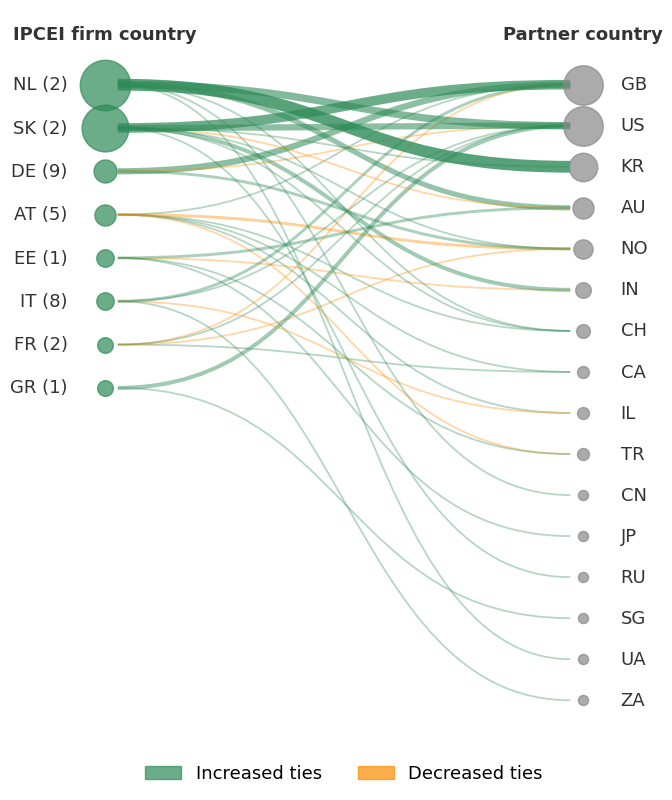

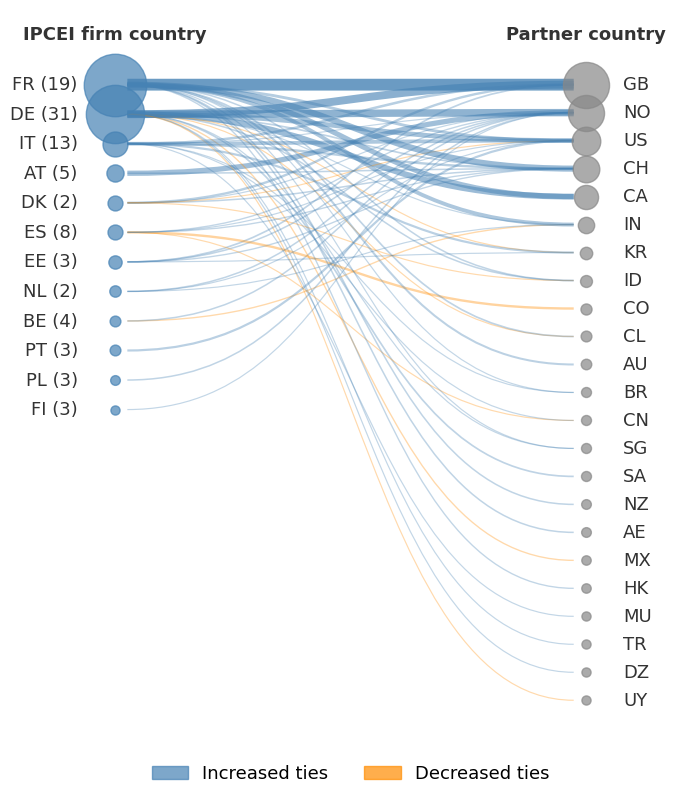

In [10]:
# ============================================================
# Sankey-style bipartite flow chart — Non-EU collaborations
# IPCEI country (left) → non-EU partner country (right)
# Delta: post minus pre, ±12 months around first treatment cohort
# Hydrogen only
# ============================================================

def build_bipartite_flows_noneu(partnership_master, firm_master_ipcei,
                                 treated_names, tech_col, treatment_date,
                                 eu_codes, window_months=12, min_flow=3):
    primary_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["primary_country"].str.strip().str.upper()
    ))

    all_ipcei = set(firm_master_ipcei.loc[
        firm_master_ipcei["treated_any"].fillna(0).astype(int) == 1,
        "Linkedin_name"
    ])

    t         = pd.Timestamp(treatment_date)
    pre_start = t - pd.DateOffset(months=window_months)
    post_end  = t + pd.DateOffset(months=window_months)

    def get_flows(start, end):
        p = partnership_master.copy()
        p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
        p = p[(p["post_date"] >= pd.Timestamp(start)) &
              (p["post_date"] <  pd.Timestamp(end))]
        p = p[p[tech_col] == 1]
        p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

        # Exclude IPCEI-IPCEI pairs
        p = p[~(p["source"].isin(all_ipcei) & p["target"].isin(all_ipcei))]

        p["src_country"] = p["source"].map(primary_map)
        p["tgt_country"] = p["target"].map(primary_map)

        p = p.dropna(subset=["src_country", "tgt_country"])

        # Remove invalid country codes
        valid_iso2 = lambda x: isinstance(x, str) and len(x) == 2 and x.isalpha()
        p = p[p["src_country"].apply(valid_iso2) & p["tgt_country"].apply(valid_iso2)]


        # IPCEI firm must be in EU, partner must be outside EU
        rows = []
        for _, row in p.iterrows():
            if row["source"] in treated_names:
                ipcei_country   = row["src_country"]
                partner_country = row["tgt_country"]
            else:
                ipcei_country   = row["tgt_country"]
                partner_country = row["src_country"]

            # IPCEI firm must be EU-headquartered
            # Partner must be non-EU
            if (ipcei_country in eu_codes and
                    partner_country not in eu_codes and
                    partner_country != ipcei_country):
                rows.append({
                    "ipcei_country":    ipcei_country,
                    "partner_country":  partner_country,
                    "collaboration_id": row["collaboration_id"]
                })

        if not rows:
            return pd.DataFrame(columns=["ipcei_country",
                                          "partner_country", "n"])
        df = pd.DataFrame(rows)
        return (
            df.groupby(["ipcei_country", "partner_country"])
              ["collaboration_id"].nunique()
              .reset_index(name="n")
        )

    flows_pre  = get_flows(pre_start, t)
    flows_post = get_flows(t, post_end)

    delta = flows_pre.rename(columns={"n": "n_pre"}).merge(
        flows_post.rename(columns={"n": "n_post"}),
        on=["ipcei_country", "partner_country"], how="outer"
    ).fillna(0)

    delta["n_delta"] = delta["n_post"] - delta["n_pre"]
    delta = delta[delta["n_delta"].abs() >= min_flow]

    print(f"  Flows above threshold: {len(delta)}")
    print(f"  IPCEI countries:   {sorted(delta['ipcei_country'].unique())}")
    print(f"  Partner countries: {sorted(delta['partner_country'].unique())}")

    return delta


# ── EU codes ──────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

battery_treated  = set(battery_cs[battery_cs["is_treated"]  == 1]["Linkedin_name"])
hydrogen_treated = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"])

# ── Build flows ───────────────────────────────────────────────────────────────
print("Battery:")
battery_delta_noneu = build_bipartite_flows_noneu(
    partnership_master, firm_master_ipcei,
    treated_names  = battery_treated,
    tech_col       = "Battery",
    treatment_date = "2021-01-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 1
)

print("\nHydrogen:")
hydrogen_delta_noneu = build_bipartite_flows_noneu(
    partnership_master, firm_master_ipcei,
    treated_names  = hydrogen_treated,
    tech_col       = "Hydrogen",
    treatment_date = "2022-07-01",
    eu_codes       = EU_CODES,
    window_months  = 12,
    min_flow       = 3
)

# ── Shared figure height ──────────────────────────────────────────────────────
n_right_b    = battery_delta_noneu["partner_country"].nunique()
n_right_h    = hydrogen_delta_noneu["partner_country"].nunique()
n_right_max  = max(n_right_b, n_right_h)
shared_height = max(5, 0.35 * n_right_max)

print(f"\nBattery right countries:  {n_right_b}")
print(f"Hydrogen right countries: {n_right_h}")
print(f"Shared figure height:     {shared_height:.1f}")

# ── Plot Battery ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, battery_delta_noneu,
                    color       = COLORS["two"][1],
                    firm_counts = battery_firm_counts)
plt.tight_layout()
save_fig(fig, "results_descriptive",
         "collaborations_battery_noneu_bipartite")
plt.show()

# ── Plot Hydrogen ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, shared_height))
draw_bipartite_flow(ax, hydrogen_delta_noneu,
                    color       = COLORS["two"][0],
                    firm_counts = hydrogen_firm_counts)
plt.tight_layout()
save_fig(fig, "results_descriptive",
         "collaborations_hydrogen_noneu_bipartite")
plt.show()

Battery avg monthly collabs per firm (±12 months):
geo_cat  Domestic  Cross-border EU  Non-EU
period                                    
post         0.62             0.69    1.01
pre          0.22             0.23    0.37

Hydrogen avg monthly collabs per firm (±12 months):
geo_cat  Domestic  Cross-border EU  Non-EU
period                                    
post         4.57             4.17    5.11
pre          3.78             3.20    4.28


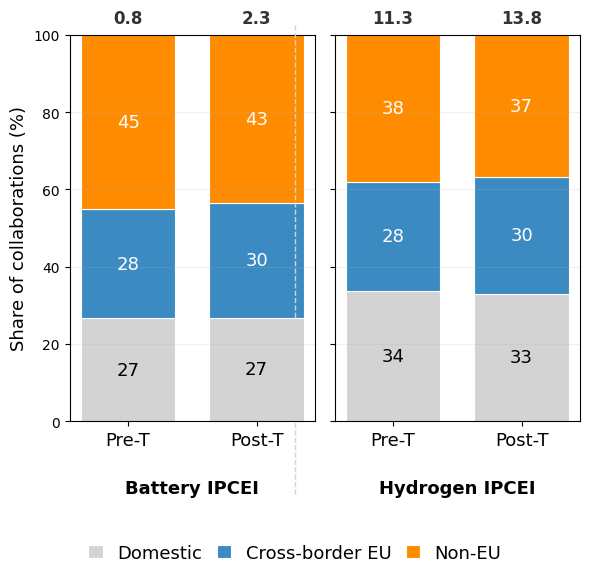

In [23]:
# ============================================================
# Geographic composition of collaborations — pre vs post treatment
# Battery: fixed split (2020 vs 2021-25)
# Hydrogen: firm-specific treatment date split
# Three categories: Domestic, Cross-border EU, Non-EU
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

# ── Setup ─────────────────────────────────────────────────────────────────────
EU_CODES = {
    "AT","BE","BG","HR","CY","CZ","DK","EE","FI","FR","DE","GR",
    "HU","IE","IT","LV","LT","LU","MT","NL","PL","PT","RO","SK",
    "SI","ES","SE"
}

AXIS_LABEL_FS = 13
TICK_FS       = 13
GROUP_LABEL_FS = 13
LEGEND_FS     = 13
BAR_TEXT_FS   = 13

geo_categories  = ["Domestic", "Cross-border EU", "Non-EU"]
geo_colors = {
    "Domestic":        "lightgrey",
    "Cross-border EU": plt.cm.Blues(0.65),
    "Non-EU":          "darkorange",
}

# ── Primary country lookup ────────────────────────────────────────────────────
primary_map = dict(zip(
    fm["Linkedin_name"],
    fm["primary_country"].str.strip().str.upper()
))

# ── Firm flags and treatment dates ───────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

base["first_battery_date"]  = pd.to_datetime(
    base["first_battery_date"],  errors="coerce")
base["first_hydrogen_date"] = pd.to_datetime(
    base["first_hydrogen_date"], errors="coerce")

# Treatment date lookup per firm per technology
battery_treat_map  = dict(zip(
    base.loc[base["is_battery"],  "Linkedin_name"],
    base.loc[base["is_battery"],  "first_battery_date"]
))
hydrogen_treat_map = dict(zip(
    base.loc[base["is_hydrogen"], "Linkedin_name"],
    base.loc[base["is_hydrogen"], "first_hydrogen_date"]
))

# ── Prep partnerships ─────────────────────────────────────────────────────────
p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
p = p.loc[p["post_date"].between(
    pd.Timestamp("2020-01-01"), pd.Timestamp("2025-12-31")
)].copy()

p["src_country"] = p["source"].map(primary_map)
p["tgt_country"] = p["target"].map(primary_map)

valid_iso2 = lambda x: isinstance(x, str) and len(x) == 2 and x.isalpha()
p = p[p["src_country"].apply(valid_iso2) & p["tgt_country"].apply(valid_iso2)]

def classify_geo(src, tgt, eu_codes):
    if src == tgt:
        return "Domestic"
    elif src in eu_codes and tgt in eu_codes:
        return "Cross-border EU"
    else:
        return "Non-EU"

p["geo_cat"] = p.apply(
    lambda r: classify_geo(r["src_country"], r["tgt_country"], EU_CODES),
    axis=1
)

# ── Build firm-level pre/post geographic shares ───────────────────────────────
def build_geo_counts_firmwise(p, ipcei_names, treat_map,
                               window_months=12):
    """
    For each IPCEI firm, compute average monthly collaboration counts
    by geographic category in ±window_months around treatment date.
    """
    records = []

    for firm in ipcei_names:
        t_date = treat_map.get(firm)
        if pd.isna(t_date):
            continue

        pre_start = t_date - pd.DateOffset(months=window_months)
        post_end  = t_date + pd.DateOffset(months=window_months)

        firm_p = p.loc[
            (p["source"] == firm) | (p["target"] == firm)
        ].copy()

        pre_p  = firm_p[
            (firm_p["post_date"] >= pre_start) &
            (firm_p["post_date"] <  t_date)
        ]
        post_p = firm_p[
            (firm_p["post_date"] >= t_date) &
            (firm_p["post_date"] <  post_end)
        ]

        for period, sub in [("pre", pre_p), ("post", post_p)]:
            n_months = window_months  # fixed window — both periods same length
            for cat in geo_categories:
                n = sub.loc[
                    sub["geo_cat"] == cat, "collaboration_id"
                ].nunique()
                records.append({
                    "firm":    firm,
                    "period":  period,
                    "geo_cat": cat,
                    "monthly": n / n_months
                })

    df = pd.DataFrame(records)
    if df.empty:
        return pd.DataFrame(columns=["period"] + geo_categories)

    avg = (
        df.groupby(["period", "geo_cat"])["monthly"]
          .mean()
          .reset_index()
    )
    return avg.pivot(index="period", columns="geo_cat", values="monthly")\
              .fillna(0)\
              .reindex(columns=geo_categories)

# ── Build geo counts ──────────────────────────────────────────────────────────
battery_geo  = build_geo_counts_firmwise(
    p, battery_ipcei,  battery_treat_map,  window_months=12)
hydrogen_geo = build_geo_counts_firmwise(
    p, hydrogen_ipcei, hydrogen_treat_map, window_months=12)

print("Battery avg monthly collabs per firm (±12 months):")
print(battery_geo.round(2))
print("\nHydrogen avg monthly collabs per firm (±12 months):")
print(hydrogen_geo.round(2))

# ── Convert to shares + totals ────────────────────────────────────────────────
def to_shares_and_totals(geo_df):
    totals = geo_df.sum(axis=1)
    shares = geo_df.div(totals, axis=0) * 100
    return shares, totals

battery_shares,  battery_totals  = to_shares_and_totals(battery_geo)
hydrogen_shares, hydrogen_totals = to_shares_and_totals(hydrogen_geo)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(6, 5.6), sharey=True)

data_map = {
    "Battery IPCEI":  battery_shares,
    "Hydrogen IPCEI": hydrogen_shares,
}
totals_map = {
    "Battery IPCEI":  battery_totals,
    "Hydrogen IPCEI": hydrogen_totals,
}

geo_categories = ["Domestic", "Cross-border EU", "Non-EU"]
geo_colors = {
    "Domestic":        "lightgrey",
    "Cross-border EU": plt.cm.Blues(0.65),
    "Non-EU":          "darkorange",
}

period_keys   = ["pre", "post"]
bar_width     = 0.32
group_gap     = 0.08

for ax, fg in zip(axes, ["Battery IPCEI", "Hydrogen IPCEI"]):
    shares  = data_map[fg]
    totals  = totals_map[fg]

    x_positions = {}
    for j, pk in enumerate(period_keys):
        x_positions[pk] = j * (bar_width + group_gap)

    bottoms = {pk: 0.0 for pk in period_keys}

    for cat in geo_categories:
        xs = [x_positions[pk] for pk in period_keys]
        ys = [
            float(shares.loc[pk, cat]) if pk in shares.index else 0.0
            for pk in period_keys
        ]
        bs = [bottoms[pk] for pk in period_keys]

        ax.bar(
            xs, ys, bottom=bs,
            width=bar_width * 0.92,
            label=cat,
            color=geo_colors[cat],
            edgecolor="white", linewidth=0.8
        )

        for x, b, v, cat_ in zip(xs, bs, ys, [cat, cat]):
            if v >= 9:
                ax.text(
                    x, b + v / 2, f"{v:.0f}",
                    ha="center", va="center",
                    fontsize=BAR_TEXT_FS,
                    color="white" if cat != "Domestic" else "black"
                )

        for pk in period_keys:
            bottoms[pk] += (
                float(shares.loc[pk, cat]) if pk in shares.index else 0.0
            )

    # Total monthly count above each bar
    for pk in period_keys:
        x = x_positions[pk]
        total = float(totals.loc[pk]) if pk in totals.index else 0.0
        ax.text(
            x, 102, f"{total:.1f}",
            ha="center", va="bottom",
            fontsize=BAR_TEXT_FS - 1,
            color="#333333",
            fontweight="bold"
        )

    # x-axis labels
    ax.set_xticks([x_positions[pk] for pk in period_keys])
    ax.set_xticklabels(["Pre-T", "Post-T"], fontsize=TICK_FS)

    # Group label below — same style as activity plot
    cx = np.mean([x_positions[pk] for pk in period_keys])
    ax.annotate(
        fg,
        xy=(cx, 0), xycoords=("data", "axes fraction"),
        xytext=(0, -42), textcoords="offset points",
        ha="center", va="top",
        fontsize=GROUP_LABEL_FS, fontweight="bold",
        annotation_clip=False
    )

    ax.set_ylim(0, 100)
    ax.set_yticks(np.arange(0, 101, 20))
    style_ax(ax)
    ax.grid(axis="y", alpha=0.2)
    ax.grid(axis="x", visible=False)

axes[0].set_ylabel(
    "Share of collaborations (%)", fontsize=AXIS_LABEL_FS)
axes[1].set_ylabel("")
axes[1].tick_params(axis="y", labelleft=False)

# Separator between panels
fig.add_artist(
    plt.Line2D(
        [0.5, 0.5], [0.12, 0.96],
        transform=fig.transFigure,
        color="lightgrey", linewidth=1, linestyle="--"
    )
)

# Legend
handles, labels_leg = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels_leg,
    loc="lower center", bbox_to_anchor=(0.5, -0.03),
    ncol=3, frameon=False,
    handlelength=0.8, columnspacing=0.8,
    fontsize=LEGEND_FS
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.94, wspace=0.08)
save_fig(fig, "results_descriptive",
         "collaborations_ipcei_geography_stackedbars_prepost")
plt.show()

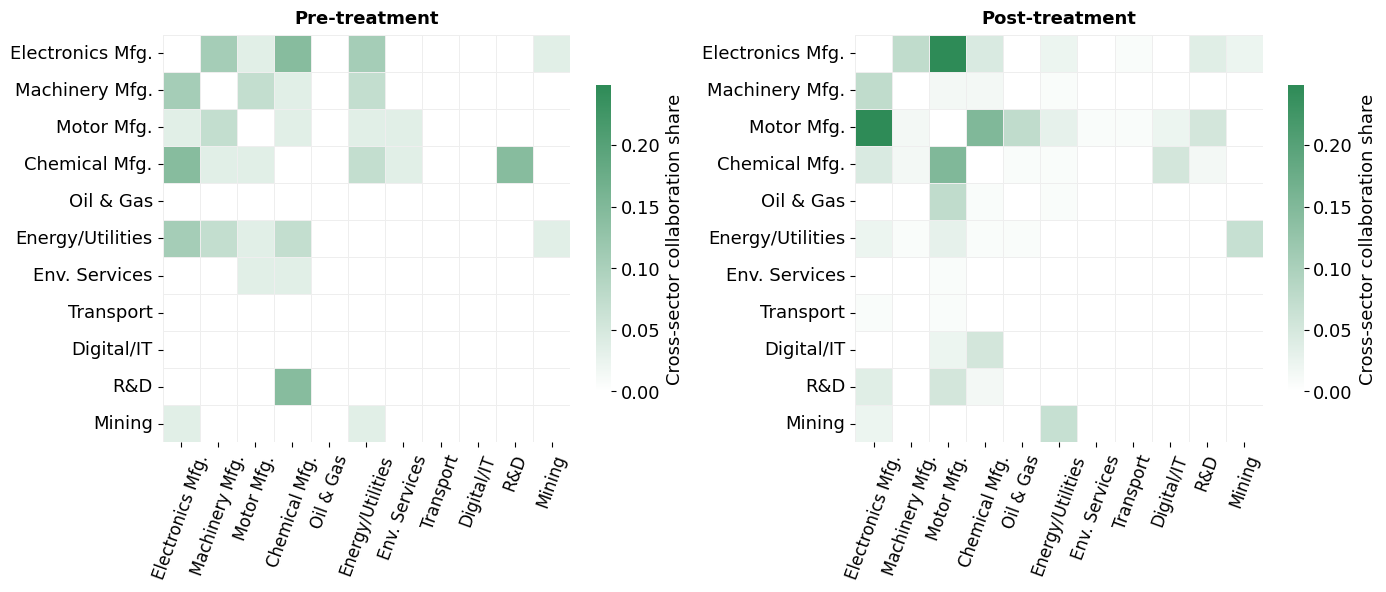

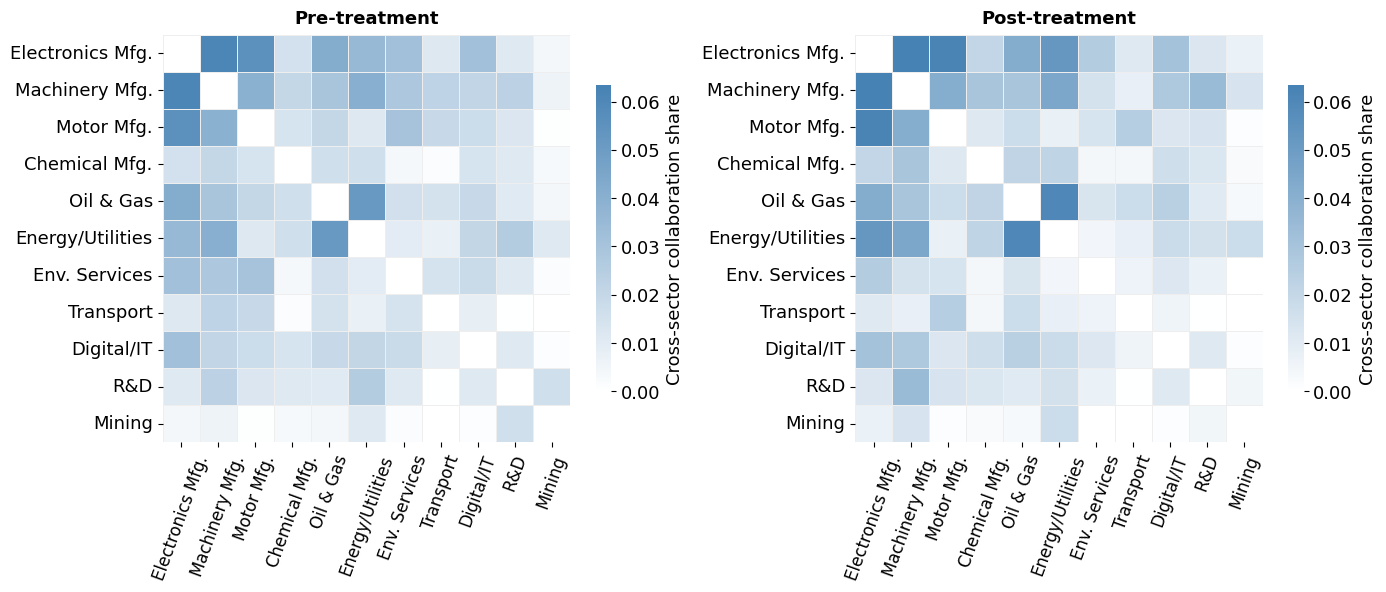

In [21]:
# ============================================================
# NACE sector pair heatmaps — cross-sector collaboration
# Pre vs post treatment, Battery and Hydrogen separately
# ============================================================

import seaborn as sns

# ── Sector label mapping ──────────────────────────────────────────────────────
sector_labels = {
    "72 — Research Services":           "R&D",
    "07 — Mining":                      "Mining",
    "38 — Environmental Services":      "Env. Services",
    "49 — Land Transport":              "Transport",
    "62 — IT Services":                 "Digital/IT",
    "20 — Chemical Manufacturing":      "Chemical Mfg.",
    "06 — Oil and Gas":                 "Oil & Gas",
    "29 — Motor Vehicle Manufacturing": "Motor Mfg.",
    "26 — Electronics Manufacturing":   "Electronics Mfg.",
    "28 — Machinery Manufacturing":     "Machinery Mfg.",
    "35 — Utilities":                   "Energy/Utilities",
}

# Sector order for consistent axis ordering
sector_order = [
    # Core manufacturing value chain
    "Electronics Mfg.", "Machinery Mfg.", "Motor Mfg.", "Chemical Mfg.",
    # Energy system
    "Oil & Gas", "Energy/Utilities", "Env. Services",
    # Enabling / upstream
    "Transport", "Digital/IT", "R&D", "Mining"
]

def build_sector_matrix(partnership_master, firm_master_ipcei,
                         treated_names, tech_col,
                         start_date, end_date,
                         sector_labels, sector_order):
    """
    Build normalised sector-pair collaboration matrix.
    Rows and columns = NACE sectors of source and target firms.
    Values = share of total cross-sector collaborations.
    """
    # Sector lookup
    sector_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["nace2_industry"].map(sector_labels)
    ))

    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
    p = p[(p["post_date"] >= pd.Timestamp(start_date)) &
          (p["post_date"] <  pd.Timestamp(end_date))]
    p = p[p[tech_col] == 1]
    p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

    p["src_sector"] = p["source"].map(sector_map)
    p["tgt_sector"] = p["target"].map(sector_map)

    # Keep only pairs where both sectors are known and different
    p = p.dropna(subset=["src_sector", "tgt_sector"])
    p = p[p["src_sector"] != p["tgt_sector"]]

    # Normalise pair order
    p["sec_a"] = p.apply(
        lambda r: min(r["src_sector"], r["tgt_sector"]), axis=1)
    p["sec_b"] = p.apply(
        lambda r: max(r["src_sector"], r["tgt_sector"]), axis=1)

    flows = (
        p.groupby(["sec_a", "sec_b"])["collaboration_id"]
         .nunique()
         .reset_index(name="n")
    )

    # Normalise to shares
    total = flows["n"].sum()
    flows["share"] = flows["n"] / total if total > 0 else 0

    # Build symmetric matrix
    sectors = [s for s in sector_order
               if s in flows["sec_a"].values or s in flows["sec_b"].values]

    matrix = pd.DataFrame(0.0, index=sectors, columns=sectors)
    for _, row in flows.iterrows():
        if row["sec_a"] in matrix.index and row["sec_b"] in matrix.columns:
            matrix.loc[row["sec_a"], row["sec_b"]] = row["share"]
            matrix.loc[row["sec_b"], row["sec_a"]] = row["share"]

    return matrix


def plot_sector_heatmaps(battery_cs, hydrogen_cs,
                          partnership_master, firm_master_ipcei,
                          sector_labels, sector_order):

    configs = [
        (battery_cs,  "Battery",  "2021-01-01",
         "2020-01-01", "2021-01-01", "2022-01-01",
         COLORS["two"][1], "collaborations_battery_sector_heatmap"),
        (hydrogen_cs, "Hydrogen", "2022-07-01",
         "2021-07-01", "2022-07-01", "2023-07-01",
         COLORS["two"][0], "collaborations_hydrogen_sector_heatmap"),
    ]

    for cs, tech_col, t_date, pre_s, pre_e, post_e, color, figname in configs:

        treated_names = set(cs[cs["is_treated"] == 1]["Linkedin_name"])

        mat_pre  = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date   = pre_s,
            end_date     = pre_e,
            sector_labels = sector_labels,
            sector_order  = sector_order
        )
        mat_post = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date   = pre_e,
            end_date     = post_e,
            sector_labels = sector_labels,
            sector_order  = sector_order
        )

        # Align matrices to same index/columns
        all_sectors = sorted(set(
            mat_pre.index.tolist() + mat_post.index.tolist()
        ), key=lambda x: sector_order.index(x) if x in sector_order else 99)

        mat_pre  = mat_pre.reindex(index=all_sectors,
                                    columns=all_sectors, fill_value=0)
        mat_post = mat_post.reindex(index=all_sectors,
                                     columns=all_sectors, fill_value=0)

        # Shared color scale
        vmax = max(mat_pre.values.max(), mat_post.values.max())

        # Custom colormap from white to technology color
        import matplotlib.colors as mcolors
        cmap = mcolors.LinearSegmentedColormap.from_list(
            "tech", ["white", color], N=256
        )

        fig, axes = plt.subplots(1, 2, figsize=(14, 7))

        for ax, mat, period_label in zip(
            axes, [mat_pre, mat_post],
            ["Pre-treatment", "Post-treatment"]
        ):
            # Mask diagonal (same-sector = 0 by construction)
            mask = np.eye(len(mat), dtype=bool)

            sns.heatmap(
                mat,
                ax          = ax,
                cmap        = cmap,
                vmin        = 0,
                vmax        = vmax,
                mask        = mask,
                linewidths  = 0.5,
                linecolor   = "#eeeeee",
                cbar        = True,
                cbar_kws    = {"shrink": 0.6,
                               "label": "Cross-sector collaboration share"},
                annot       = False,
                square      = True,
            )

            cbar = ax.collections[0].colorbar
            cbar.ax.tick_params(labelsize=13)
            cbar.set_label("Cross-sector collaboration share", fontsize=13)

            ax.set_title(period_label, fontsize=13,
                         fontweight="bold", pad=8)
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.tick_params(axis="x", rotation=70, labelsize=12)
            ax.tick_params(axis="y", rotation=0,  labelsize=13)

        plt.tight_layout()
        plt.subplots_adjust(bottom=0.25)
        save_fig(fig, "results_descriptive", figname)
        plt.show()


plot_sector_heatmaps(
    battery_cs, hydrogen_cs,
    partnership_master, firm_master_ipcei,
    sector_labels, sector_order
)

In [24]:
print(f"Missing primary_country: "
      f"{firm_master_ipcei['primary_country'].isna().sum()} / "
      f"{len(firm_master_ipcei)}")

# Among IPCEI firms specifically
ipcei = firm_master_ipcei[firm_master_ipcei["treated_any"].fillna(0).astype(int)==1]
print(f"Missing primary_country among IPCEI firms: "
      f"{ipcei['primary_country'].isna().sum()} / {len(ipcei)}")

Missing primary_country: 0 / 239782
Missing primary_country among IPCEI firms: 0 / 150


In [22]:
# ============================================================
# NACE sector pair heatmaps — change in cross-sector collaboration
# Post minus pre-treatment, Battery and Hydrogen separately
# ============================================================

import seaborn as sns
import matplotlib.colors as mcolors

def plot_sector_heatmaps_diff(
    battery_cs, hydrogen_cs,
    partnership_master, firm_master_ipcei,
    sector_labels, sector_order
):

    configs = [
        (
            battery_cs, "Battery",
            "2020-01-01", "2021-01-01", "2022-01-01",
            "collaborations_battery_sector_heatmap_diff"
        ),
        (
            hydrogen_cs, "Hydrogen",
            "2021-07-01", "2022-07-01", "2023-07-01",
            "collaborations_hydrogen_sector_heatmap_diff"
        ),
    ]

    for cs, tech_col, pre_s, pre_e, post_e, figname in configs:

        treated_names = set(cs.loc[cs["is_treated"] == 1, "Linkedin_name"])

        mat_pre = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date=pre_s,
            end_date=pre_e,
            sector_labels=sector_labels,
            sector_order=sector_order
        )

        mat_post = build_sector_matrix(
            partnership_master, firm_master_ipcei,
            treated_names, tech_col,
            start_date=pre_e,
            end_date=post_e,
            sector_labels=sector_labels,
            sector_order=sector_order
        )

        # Align matrices
        all_sectors = sorted(
            set(mat_pre.index.tolist() + mat_post.index.tolist()),
            key=lambda x: sector_order.index(x) if x in sector_order else 99
        )

        mat_pre = mat_pre.reindex(index=all_sectors, columns=all_sectors, fill_value=0)
        mat_post = mat_post.reindex(index=all_sectors, columns=all_sectors, fill_value=0)

        # Difference: post - pre
        mat_diff = mat_post - mat_pre

        # Shared symmetric scale around zero
        vmax = 0.10

        # Technology-specific diverging colormap:
        # negative = darkorange, zero = white, positive = tech color
        pos_color = COLORS["two"][1] if tech_col == "Battery" else COLORS["two"][0]
        cmap = mcolors.LinearSegmentedColormap.from_list(
            f"{tech_col.lower()}_diff",
            ["darkorange", "white", pos_color],
            N=256
        )

        fig, ax = plt.subplots(figsize=(7.2, 6.6))

        # mask diagonal since same-sector cells are zero / not used
        mat_plot = mat_diff.copy()
        mat_plot.values[np.triu_indices_from(mat_plot, k=0)] = np.nan

        sns.heatmap(
            mat_plot,
            ax=ax,
            cmap=cmap,
            center=0,
            vmin=-vmax,
            vmax=vmax,
            linewidths=0.5,
            cbar=True,
            cbar_kws={
                "shrink": 0.7,
                "label": "Change in cross-sector collaboration"
            },
            annot=False,
            square=True,
        )

        cbar = ax.collections[0].colorbar
        cbar.ax.tick_params(labelsize=13)
        cbar.set_label("Change in cross-sector collaboration", fontsize=13)

        ax.set_facecolor("white")

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=70, labelsize=12)
        ax.tick_params(axis="y", rotation=0, labelsize=13)

        plt.tight_layout()
        plt.subplots_adjust(bottom=0.24)
        save_fig(fig, "results_descriptive", figname)
        plt.show()

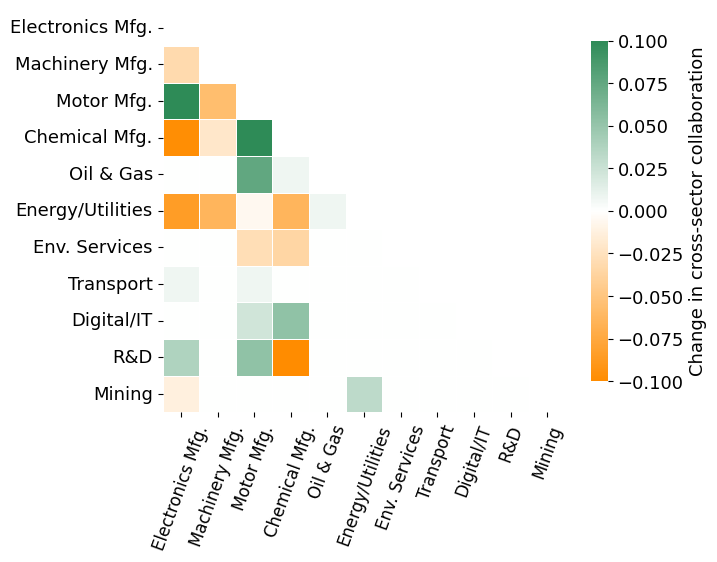

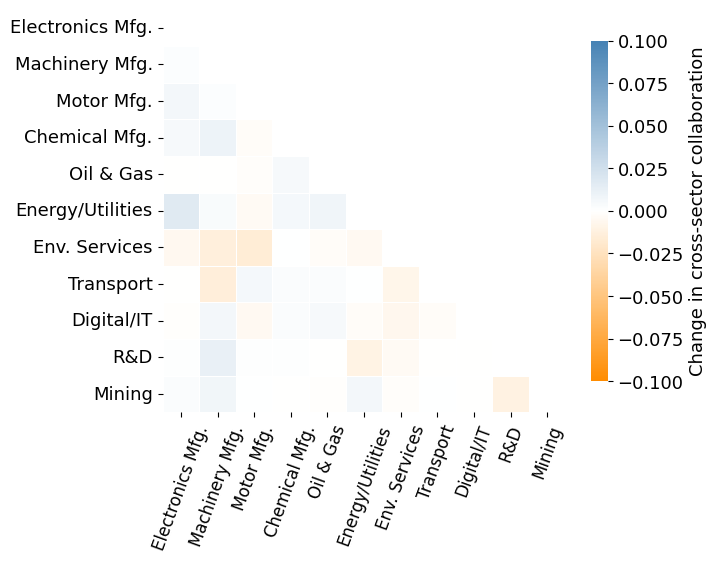

In [23]:
plot_sector_heatmaps_diff(
    battery_cs, hydrogen_cs,
    partnership_master, firm_master_ipcei,
    sector_labels, sector_order
)

Battery:
  Sector pairs: 39
  Sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'R&D', 'Mining']
  Max pair count: 462

Hydrogen:
  Sector pairs: 54
  Sectors: ['Electronics Mfg.', 'Machinery Mfg.', 'Motor Mfg.', 'Chemical Mfg.', 'Oil & Gas', 'Energy/Utilities', 'Env. Services', 'Transport', 'Digital/IT', 'R&D', 'Mining']
  Max pair count: 1097

Shared global max: 1097


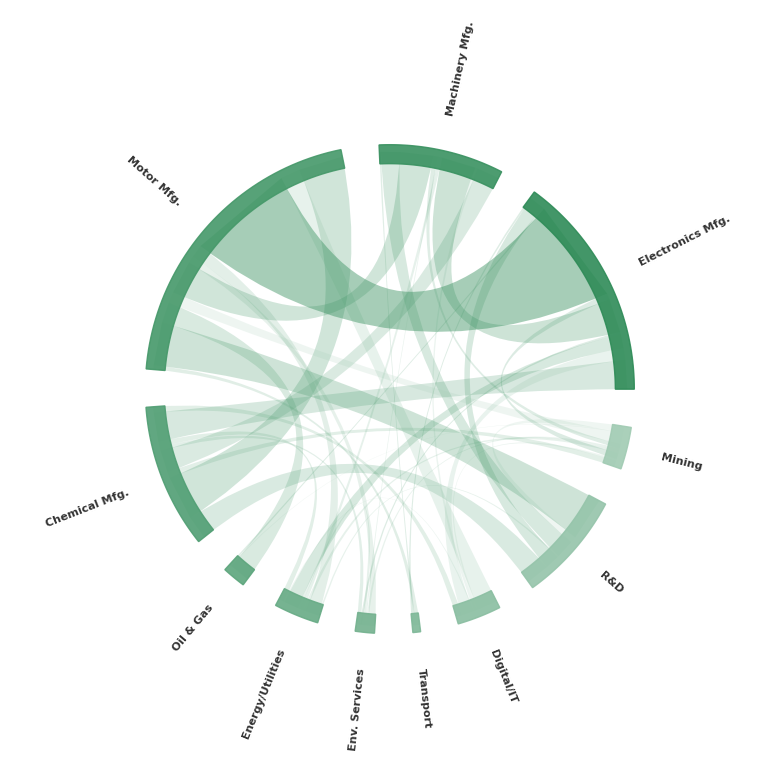

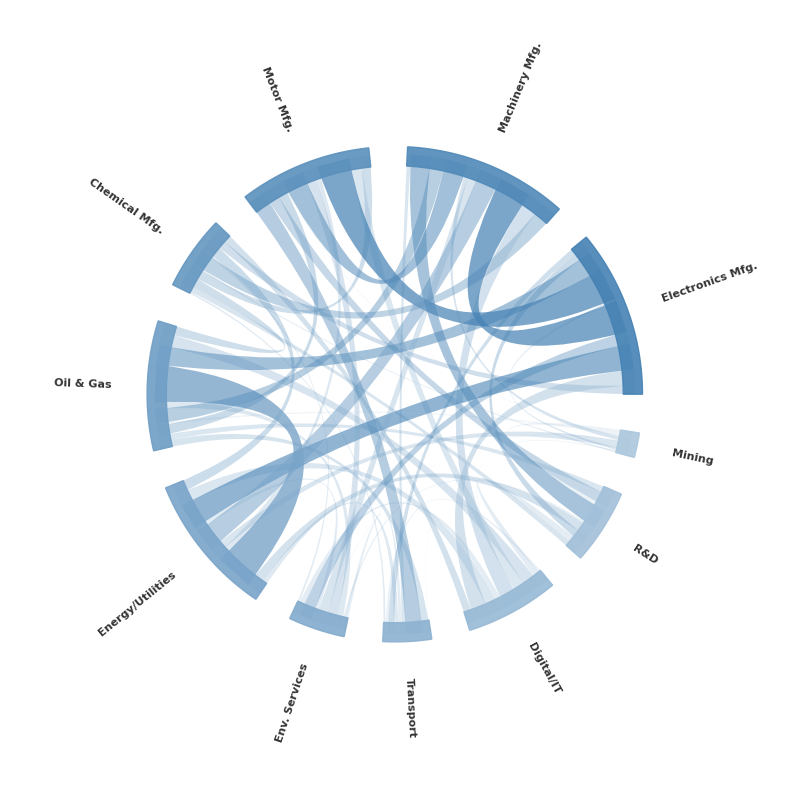

In [24]:
# ============================================================
# Chord diagram — Cross-sector collaboration structure
# Status quo: 2020-2025 total, Battery and Hydrogen separately
# Shared scaling for comparability
# ============================================================

def build_sector_flows(partnership_master, firm_master_ipcei,
                        treated_names, tech_col,
                        sector_labels, sector_order,
                        start_date="2020-01-01",
                        end_date="2025-12-31",
                        min_flow=3):
    """
    Build sector-pair collaboration counts for a given window.
    Returns flows dataframe with sec_a, sec_b, n.
    """
    sector_map = dict(zip(
        firm_master_ipcei["Linkedin_name"],
        firm_master_ipcei["nace2_industry"].map(sector_labels)
    ))

    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")
    p = p[(p["post_date"] >= pd.Timestamp(start_date)) &
          (p["post_date"] <  pd.Timestamp(end_date))]
    p = p[p[tech_col] == 1]
    p = p[p["source"].isin(treated_names) | p["target"].isin(treated_names)]

    p["src_sector"] = p["source"].map(sector_map)
    p["tgt_sector"] = p["target"].map(sector_map)

    p = p.dropna(subset=["src_sector", "tgt_sector"])
    p = p[p["src_sector"] != p["tgt_sector"]]

    p["sec_a"] = p.apply(
        lambda r: min(r["src_sector"], r["tgt_sector"]), axis=1)
    p["sec_b"] = p.apply(
        lambda r: max(r["src_sector"], r["tgt_sector"]), axis=1)

    flows = (
        p.groupby(["sec_a", "sec_b"])["collaboration_id"]
         .nunique()
         .reset_index(name="n")
    )

    flows = flows[flows["n"] >= min_flow]

    # Rename for compatibility with draw_sector_chord
    flows["country_a"] = flows["sec_a"]
    flows["country_b"] = flows["sec_b"]

    sectors_present = [s for s in sector_order
                       if s in flows["sec_a"].values or
                          s in flows["sec_b"].values]

    print(f"  Sector pairs: {len(flows)}")
    print(f"  Sectors: {sectors_present}")
    print(f"  Max pair count: {flows['n'].max()}")

    return flows, sectors_present


def draw_sector_chord_status_quo(ax, flows, sectors, color, global_max=None):
    """
    Chord diagram for sector-pair status quo.
    global_max: if provided, normalise chord thickness across diagrams
                for comparability between Battery and Hydrogen.
    """
    n = len(sectors)
    if n == 0:
        ax.text(0.5, 0.5, "No data", ha="center", va="center",
                transform=ax.transAxes)
        return

    totals = {c: 0 for c in sectors}
    for _, row in flows.iterrows():
        if row["country_a"] in totals: totals[row["country_a"]] += row["n"]
        if row["country_b"] in totals: totals[row["country_b"]] += row["n"]

    grand_total = sum(totals.values()) or 1
    gap = 0.025

    arc_pos = {}
    angle = 0
    for c in sectors:
        span = (totals[c] / grand_total) * (1 - gap * n)
        arc_pos[c] = {"start": angle, "end": angle + span}
        angle += span + gap

    for c in arc_pos:
        arc_pos[c]["start"] *= 2 * np.pi
        arc_pos[c]["end"]   *= 2 * np.pi

    base = mcolors.to_rgb(color)
    sector_colors = {}
    for i, c in enumerate(sectors):
        t = i / max(len(sectors) - 1, 1)
        lightened = tuple(base[j] + t * (1 - base[j]) * 0.55 for j in range(3))
        sector_colors[c] = lightened

    # Use global_max for shared scaling, fallback to local max
    max_n = global_max if global_max else (flows["n"].max() or 1)

    fill_pos = {c: arc_pos[c]["start"] for c in sectors}

    for _, row in flows.iterrows():
        ca, cb, n_flow = row["country_a"], row["country_b"], row["n"]
        if ca not in arc_pos or cb not in arc_pos:
            continue

        span = (n_flow / grand_total) * 2 * np.pi * (1 - gap * n)

        a0 = fill_pos[ca]; a1 = a0 + span
        b0 = fill_pos[cb]; b1 = b0 + span
        fill_pos[ca] += span
        fill_pos[cb] += span

        def pt(angle, r=1):
            return (r * np.cos(angle), r * np.sin(angle))

        verts = [
            pt(a0), (0, 0), pt(b1),
            pt(b0), (0, 0), pt(a1),
            pt(a0)
        ]
        codes = [
            Path.MOVETO, Path.CURVE3, Path.CURVE3,
            Path.LINETO, Path.CURVE3, Path.CURVE3,
            Path.CLOSEPOLY
        ]
        alpha = 0.15 + 0.65 * (n_flow / max_n)
        path  = Path(verts, codes)
        patch = mpatches.PathPatch(
            path,
            facecolor = sector_colors.get(ca, (0.5, 0.5, 0.5)),
            edgecolor = "none",
            alpha     = alpha
        )
        ax.add_patch(patch)

    # Outer arcs and labels
    R_inner, R_outer, R_label = 0.95, 1.03, 1.18

    for c in sectors:
        a_start = arc_pos[c]["start"]
        a_end   = arc_pos[c]["end"]
        mid     = (a_start + a_end) / 2

        theta   = np.linspace(a_start, a_end, 50)
        x_outer = R_outer * np.cos(theta)
        y_outer = R_outer * np.sin(theta)
        x_inner = R_inner * np.cos(theta[::-1])
        y_inner = R_inner * np.sin(theta[::-1])

        ax.fill(
            np.concatenate([x_outer, x_inner]),
            np.concatenate([y_outer, y_inner]),
            color=sector_colors.get(c, (0.5, 0.5, 0.5)), alpha=0.9
        )

        ha = "left" if np.cos(mid) > 0 else "right"
        rotation = np.degrees(mid)
        if np.cos(mid) < 0:
            rotation += 180

        ax.text(
            R_label * np.cos(mid),
            R_label * np.sin(mid),
            c, ha=ha, va="center",
            fontsize=8, fontweight="bold", color="#333333",
            rotation=rotation,
            rotation_mode="anchor"
        )

    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal")
    ax.axis("off")


# ── Build flows ───────────────────────────────────────────────────────────────
print("Battery:")
bat_flows, bat_sectors = build_sector_flows(
    partnership_master, firm_master_ipcei,
    treated_names = set(battery_cs[battery_cs["is_treated"] == 1]["Linkedin_name"]),
    tech_col      = "Battery",
    sector_labels = sector_labels,
    sector_order  = sector_order,
    start_date    = "2020-01-01",
    end_date      = "2025-12-31",
    min_flow      = 3
)

print("\nHydrogen:")
hyd_flows, hyd_sectors = build_sector_flows(
    partnership_master, firm_master_ipcei,
    treated_names = set(hydrogen_cs[hydrogen_cs["is_treated"] == 1]["Linkedin_name"]),
    tech_col      = "Hydrogen",
    sector_labels = sector_labels,
    sector_order  = sector_order,
    start_date    = "2020-01-01",
    end_date      = "2025-12-31",
    min_flow      = 3
)

# ── Shared max for comparable chord thickness ─────────────────────────────────
global_max = max(
    bat_flows["n"].max() if len(bat_flows) > 0 else 0,
    hyd_flows["n"].max() if len(hyd_flows) > 0 else 0
)
print(f"\nShared global max: {global_max}")

# ── Plot Battery ──────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))
draw_sector_chord_status_quo(ax, bat_flows, bat_sectors,
                              color      = COLORS["two"][1],
                              global_max = global_max)
plt.tight_layout()
save_fig(fig, "results_descriptive", "collaborations_battery_cross-sector_chord")
plt.show()

# ── Plot Hydrogen ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 8))
draw_sector_chord_status_quo(ax, hyd_flows, hyd_sectors,
                              color      = COLORS["two"][0],
                              global_max = global_max)
plt.tight_layout()
save_fig(fig, "results_descriptive", "collaborations_hydrogen_cross-sector_chord")
plt.show()

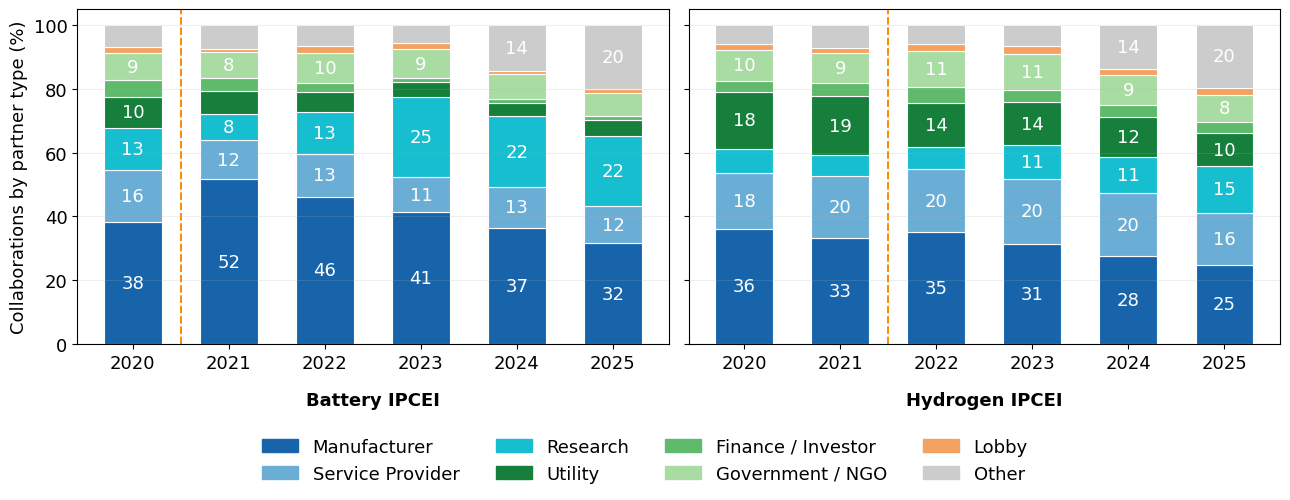

In [13]:
# ============================================================
# Partner firm type composition by year
# ============================================================

def plot_partner_firmtype_by_year():

    # --- Identify IPCEI firms and their technology + treatment date ---
    fm = firm_master_ipcei.copy()

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])

    # --- Build partner-level lookup for firm_type ---
    firm_type_lookup = (
        fm[["Linkedin_name", "firm_type"]]
        .dropna(subset=["firm_type"])
        .drop_duplicates("Linkedin_name")
        .set_index("Linkedin_name")["firm_type"]
    )

    # --- Firm type consolidation map ---
    # --- Firm type consolidation map ---
    type_map = {
        "Manufacturer":                    "Manufacturer",
        "Service Provider":                "Service Provider",
        "Consulting":                      "Service Provider",
        "Project Developer":               "Service Provider",
        "Research Institute":              "Research",
        "University":                      "Research",
        "Think Tank":                      "Research",
        "Utility":                         "Utility",
        "Financial Institution":           "Finance / Investor",
        "Investor":                        "Finance / Investor",
        "Venture Capital":                 "Finance / Investor",
        "Bank":                            "Finance / Investor",
        "Other Financing Organization":    "Finance / Investor",
        "Accelerator/Incubator":           "Finance / Investor",
        "Governmental Organization":       "Government / NGO",
        "Governmental organization":       "Government / NGO",
        "Government Organization":         "Government / NGO",
        "Government Administration":       "Government / NGO",
        "International Organization":      "Government / NGO",
        "Intergovernmental Organization":  "Government / NGO",
        "NGO":                             "Government / NGO",
        "Non Governmental Organization":   "Government / NGO",
        "Non-Governmental Organization":   "Government / NGO",
        "Non Govermental Organization":    "Government / NGO",
        "Government":                      "Government / NGO",
        "Lobby Group":                     "Lobby",
        "Industry Association":            "Lobby",
        "Trade Association":               "Lobby",
        "Professional Association":        "Lobby",
        "Professional Organization":       "Lobby",
        "Chamber of Commerce":             "Lobby",
        "Other":                           "Other",
        "Media Firm":                      "Other",
        "Event Organizer":                 "Other",
        "Mining":                          "Other",
        "0":                               "Other",
    }

    type_order = [
        "Manufacturer", "Service Provider", "Research",
        "Utility", "Finance / Investor", "Government / NGO", "Lobby", "Other"
    ]

    type_colors = {
        "Manufacturer":        plt.cm.Blues(0.80),
        "Service Provider":    plt.cm.Blues(0.50),
        "Research":            "#17becf",
        "Utility":             plt.cm.Greens(0.80),
        "Finance / Investor":  plt.cm.Greens(0.55),
        "Government / NGO":    plt.cm.Greens(0.35),
        "Lobby":               "#f4a261",   # warm orange
        "Other":               "#cccccc",
    }

    results = {}

    for tech, focal_firms, date_col in [
        ("Battery",  battery_firms,  "first_battery_date"),
        ("Hydrogen", hydrogen_firms, "first_hydrogen_date"),
    ]:
        # Partnerships where source is a focal IPCEI firm
        pm = partnership_master.copy()
        pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
        pm = pm[pm["source"].isin(focal_firms)].copy()

        # Merge partner firm_type
        pm["partner_type_raw"] = pm["target"].map(firm_type_lookup)
        pm["partner_type"] = (
            pm["partner_type_raw"]
            .astype("string")
            .str.split(",").str[0]   # take first role if multiple
            .str.strip()
            .map(type_map)
            .fillna("Other")
        )

        pm["year"] = pm["post_date"].dt.year
        pm = pm[pm["year"].between(2020, 2025)]

        # Share per year
        yearly = (
            pm.groupby(["year", "partner_type"])
            .size()
            .reset_index(name="n")
        )
        yearly["share"] = yearly.groupby("year")["n"].transform(
            lambda x: x / x.sum() * 100
        )

        pivot = (
            yearly.pivot(index="year", columns="partner_type", values="share")
            .reindex(columns=type_order)
            .fillna(0)
        )
        results[tech] = pivot

    # --- Plot ---
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

    for ax, (tech, pivot) in zip(axes, results.items()):
        bottom = np.zeros(len(pivot))
        x = np.arange(len(pivot))

        for ptype in type_order:
            if ptype not in pivot.columns:
                continue
            vals = pivot[ptype].values
            ax.bar(x, vals, bottom=bottom,
                   color=type_colors[ptype],
                   label=ptype, width=0.6,
                   edgecolor="white", linewidth=0.8)
            for xi, (v, b) in enumerate(zip(vals, bottom)):
                if v >= 8:
                    ax.text(xi, b + v / 2, f"{v:.0f}",
                            ha="center", va="center",
                            fontsize=13, color="white")
            bottom += vals

        ax.set_xticks(x)
        ax.set_xticklabels(pivot.index.astype(int), rotation=0)
        #ax.set_xlabel("Year")
        ax.set_ylabel("Collaborations by partner type (%)" if ax == axes[0] else "", fontsize=13)
        ax.axvline(
            x=(2021 if tech == "Battery" else 2022) - 2020 - 0.5,
            linestyle="--", color="darkorange", linewidth=1.4,
            label="First approval"
        )
        style_ax(ax)
        ax.grid(axis="y", alpha=0.2)
        ax.grid(axis="x", visible=False)
        ax.tick_params(axis="both", labelsize=13)

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.3)

    # Technology titles below each axis, above legend
    for ax, title in zip(axes, ["Battery IPCEI", "Hydrogen IPCEI"]):
        x_center = ax.get_position().x0 + ax.get_position().width / 2
        fig.text(x_center, 0.17, title,
                 ha="center", va="bottom",
                 fontsize=13, fontweight="bold")

    # Patch handles for firm types only (no "First approval")
    handles = [
        mpatches.Patch(color=type_colors[t], label=t) for t in type_order
    ]

    fig.legend(handles=handles, loc="lower center", ncol=4,
               frameon=False, fontsize=13,
               bbox_to_anchor=(0.5, -0.01))

    # Draw "First approval" line on each axis without adding to legend
    for ax, tech in zip(axes, ["Battery", "Hydrogen"]):
        ax.axvline(
            x=(2021 if tech == "Battery" else 2022) - 2020 - 0.5,
            linestyle="--", color="darkorange", linewidth=1.4,
        )

    save_fig(fig, "results_descriptive", "collaborations_partner_firmtype_yearly_barchart")
    plt.show()

plot_partner_firmtype_by_year()

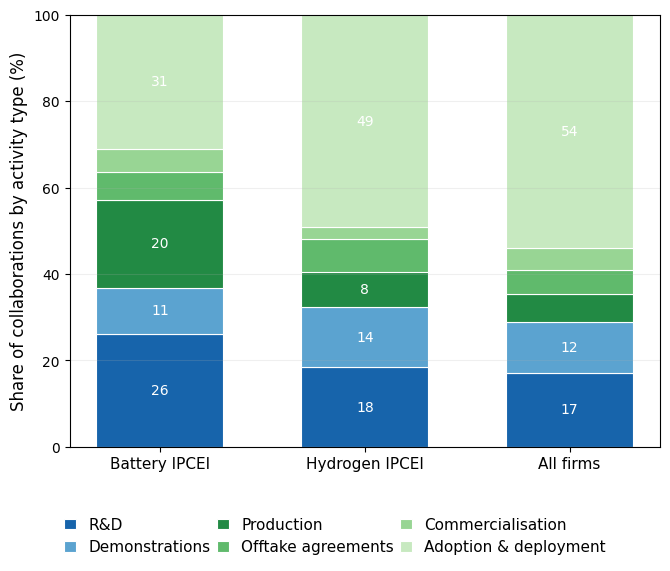

In [16]:
# ============================================================
# Collaboration activities: innovation pipeline composition
# Simple stacked bars — Hydrogen IPCEI, Battery IPCEI, All firms
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

# ── Activity columns and clean names ─────────────────────────────────────────
innovation_cols = [
    "r_and_d_collaborations",
    "demonstrations_and_pilots",
    "production_and_manufacturing",
    "offtake_agreements_and_futures",
    "commercialisation_and_product_launches",
    "adoption_and_deployments",
]
innovation_cols = [c for c in innovation_cols if c in p.columns]

col_labels = {
    "r_and_d_collaborations":               "R&D",
    "demonstrations_and_pilots":            "Demonstrations",
    "commercialisation_and_product_launches": "Commercialisation",
    "production_and_manufacturing":         "Production",
    "offtake_agreements_and_futures":       "Offtake agreements",
    "adoption_and_deployments":             "Adoption & deployment",
}

cat_order = [col_labels[c] for c in innovation_cols]

category_colors = {
    "R&D":                    plt.cm.Blues(0.80),
    "Demonstrations":         plt.cm.Blues(0.55),
    "Production":             plt.cm.Greens(0.75),
    "Offtake agreements":     plt.cm.Greens(0.55),
    "Commercialisation":      plt.cm.Greens(0.40),
    "Adoption & deployment":  plt.cm.Greens(0.25),
}

# ── Firm flags ────────────────────────────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

# ── Reshape to endpoint level ─────────────────────────────────────────────────
tmp = p.copy()
for col in innovation_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + innovation_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id"] + innovation_cols]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])
endp_full = endp.merge(
    base[["Linkedin_name", "is_hydrogen", "is_battery", "is_ipcei"]],
    on="Linkedin_name", how="left"
)

# Rename columns to clean labels
endp_full = endp_full.rename(columns=col_labels)

# ── Build shares ──────────────────────────────────────────────────────────────
group_specs = {
    "Hydrogen IPCEI": endp_full.loc[endp_full["is_ipcei"] & endp_full["is_hydrogen"]],
    "Battery IPCEI":  endp_full.loc[endp_full["is_ipcei"] & endp_full["is_battery"]],
    "All firms":      endp_full.copy(),
}

records = []
for firm_group, sub in group_specs.items():
    for cat in cat_order:
        n = sub.loc[sub[cat] == 1, "collaboration_id"].nunique()
        records.append({"firm_group": firm_group, "category": cat, "n": n})

df = pd.DataFrame(records)
df["share"] = df.groupby("firm_group")["n"].transform(
    lambda x: 100 * x / x.sum() if x.sum() > 0 else 0
)

plot_df = (
    df.pivot(index="firm_group", columns="category", values="share")
      .fillna(0)
      .reindex(["Battery IPCEI", "Hydrogen IPCEI", "All firms"])
)[cat_order]

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6.8, 5.8))

x      = np.arange(len(plot_df))
bottom = np.zeros(len(plot_df))

for cat in cat_order:
    vals = plot_df[cat].values
    ax.bar(x, vals, bottom=bottom, width=0.62,
           label=cat,
           color=category_colors[cat],
           edgecolor="white", linewidth=0.8)
    for i, (b, v) in enumerate(zip(bottom, vals)):
        if v >= 8:
            ax.text(x[i], b + v / 2, f"{v:.0f}",
                    ha="center", va="center", fontsize=10, color="white")
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, fontsize=11)
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel("Share of collaborations by activity type (%)", fontsize=12)
style_ax(ax)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

handles, labels_leg = ax.get_legend_handles_labels()
fig.legend(handles, labels_leg,
           loc="lower center", bbox_to_anchor=(0.5, 0.01),
           ncol=3,
           frameon=False,
           handlelength=0.8,
           columnspacing=0.4,
           fontsize=11)

plt.tight_layout()
plt.subplots_adjust(bottom=0.22)
save_fig(fig, "results_descriptive",
         "collaborations_ipcei_innovation_stackedbars_simple")
plt.show()

/var/folders/1w/t9ryrq_57m77f4wzbw78745m044mx9/T/ipykernel_39546/149548896.py:146: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  v = float(plot_df2.loc[(fg, pk), cat])


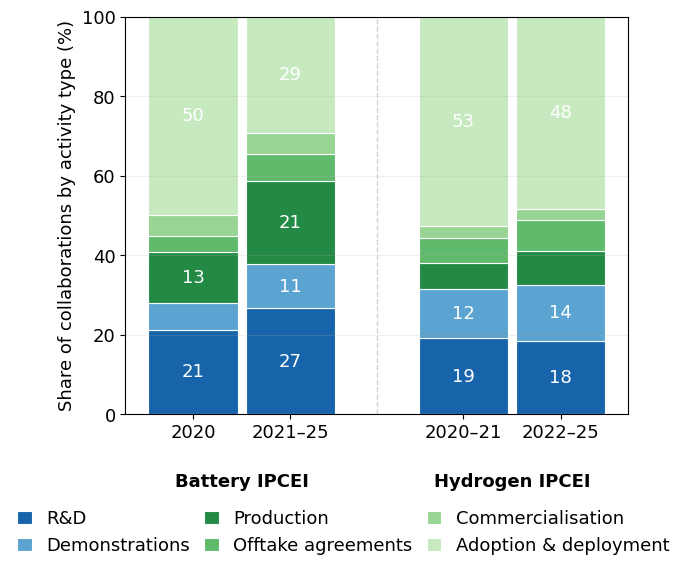

In [10]:
# ============================================================
# Collaboration activities: innovation pipeline composition
# Pre/post stacked bars — Battery and Hydrogen, tech-specific periods
# ============================================================

fm = firm_master_ipcei.copy()
p  = partnership_master.copy()

date_col = "post_date"

# ── Activity columns and clean names ─────────────────────────────────────────
innovation_cols = [
    "r_and_d_collaborations",
    "demonstrations_and_pilots",
    "production_and_manufacturing",
    "offtake_agreements_and_futures",
    "commercialisation_and_product_launches",
    "adoption_and_deployments",
]
innovation_cols = [c for c in innovation_cols if c in p.columns]

col_labels = {
    "r_and_d_collaborations":               "R&D",
    "demonstrations_and_pilots":            "Demonstrations",
    "commercialisation_and_product_launches": "Commercialisation",
    "production_and_manufacturing":         "Production",
    "offtake_agreements_and_futures":       "Offtake agreements",
    "adoption_and_deployments":             "Adoption & deployment",
}

cat_order = [col_labels[c] for c in innovation_cols]

category_colors = {
    "R&D":                    plt.cm.Blues(0.80),
    "Demonstrations":         plt.cm.Blues(0.55),
    "Production":             plt.cm.Greens(0.75),
    "Offtake agreements":     plt.cm.Greens(0.55),
    "Commercialisation":      plt.cm.Greens(0.40),
    "Adoption & deployment":  plt.cm.Greens(0.25),
}

# ── Font sizes ────────────────────────────────────────────────────────────────
AXIS_LABEL_FS = 13
TICK_FS = 13
GROUP_LABEL_FS = 13
LEGEND_FS = 13
BAR_TEXT_FS = 13

# ── Firm flags ────────────────────────────────────────────────────────────────
base = fm.drop_duplicates("Linkedin_name").copy()
types_lc = base["ipcei_types"].astype("string").str.lower()
base["is_hydrogen"] = types_lc.str.contains("hydrogen", na=False)
base["is_battery"]  = types_lc.str.contains("battery",  na=False)
base["is_ipcei"]    = base["treated_any"].fillna(0).astype(int) == 1

# ── Reshape to endpoint level ─────────────────────────────────────────────────
tmp = p.copy()
for col in innovation_cols:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce").fillna(0).astype(int)
tmp["year"] = pd.to_datetime(tmp[date_col], errors="coerce").dt.year
tmp = tmp.loc[tmp["year"].between(2020, 2025)].copy()

src = tmp.rename(columns={"source": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id", "year"] + innovation_cols]
tgt = tmp.rename(columns={"target": "Linkedin_name"})[
    ["Linkedin_name", "collaboration_id", "year"] + innovation_cols]

endp = pd.concat([src, tgt], ignore_index=True).dropna(subset=["Linkedin_name"])
endp_full = endp.merge(
    base[["Linkedin_name", "is_hydrogen", "is_battery", "is_ipcei"]],
    on="Linkedin_name", how="left"
)
endp_full = endp_full.rename(columns=col_labels)

# ── Technology-specific periods ───────────────────────────────────────────────
period_map = {
    "Battery IPCEI": {
        "pre":  ("2020",       lambda y: y == 2020),
        "post": ("2021–25", lambda y: y.between(2021, 2025)),
    },
    "Hydrogen IPCEI": {
        "pre":  ("2020–21",  lambda y: y.between(2020, 2021)),
        "post": ("2022–25", lambda y: y.between(2022, 2025)),
    }
}

records2 = []
for firm_group, periods in period_map.items():
    firm_mask = (
        endp_full["is_ipcei"] & endp_full["is_battery"]
        if firm_group == "Battery IPCEI"
        else endp_full["is_ipcei"] & endp_full["is_hydrogen"]
    )
    sub_fg = endp_full.loc[firm_mask].copy()

    for period_key, (period_label, year_fn) in periods.items():
        sub_period = sub_fg.loc[year_fn(sub_fg["year"])]
        for cat in cat_order:
            n = sub_period.loc[sub_period[cat] == 1, "collaboration_id"].nunique()
            records2.append({
                "firm_group":   firm_group,
                "period_key":   period_key,
                "period_label": period_label,
                "category":     cat,
                "n":            n
            })

df2 = pd.DataFrame(records2)
df2["share"] = df2.groupby(["firm_group", "period_key"])["n"].transform(
    lambda x: 100 * x / x.sum() if x.sum() > 0 else 0
)

plot_df2 = (
    df2.pivot(
        index=["firm_group", "period_key", "period_label"],
        columns="category", values="share"
    )
    .fillna(0)
    .reindex(columns=cat_order)
)

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 5.6))

firm_order2 = ["Battery IPCEI", "Hydrogen IPCEI"]
period_keys = ["pre", "post"]
bar_width   = 0.32
group_gap   = 0.25

x_positions   = {}
group_centers = []
for i, fg in enumerate(firm_order2):
    base_x = i * (len(period_keys) * bar_width + group_gap)
    for j, pk in enumerate(period_keys):
        x_positions[(fg, pk)] = base_x + j * bar_width
    group_centers.append(base_x + (len(period_keys) - 1) * bar_width / 2)

bottoms_dict = {(fg, pk): 0.0 for fg in firm_order2 for pk in period_keys}

for cat in cat_order:
    xs, ys, bs = [], [], []
    for fg in firm_order2:
        for pk in period_keys:
            xs.append(x_positions[(fg, pk)])
            try:
                v = float(plot_df2.loc[(fg, pk), cat])
            except KeyError:
                v = 0.0
            ys.append(v)
            bs.append(bottoms_dict[(fg, pk)])

    ax.bar(
        xs, ys, bottom=bs,
        width=bar_width * 0.92,
        label=cat,
        color=category_colors[cat],
        edgecolor="white", linewidth=0.8
    )

    for x, b, v in zip(xs, bs, ys):
        if v >= 9:
            ax.text(
                x, b + v / 2, f"{v:.0f}",
                ha="center", va="center",
                fontsize=BAR_TEXT_FS, color="white"
            )

    idx = 0
    for fg in firm_order2:
        for pk in period_keys:
            bottoms_dict[(fg, pk)] += ys[idx]
            idx += 1

# x-axis period labels
tick_xs, tick_labels = [], []
for fg in firm_order2:
    for pk in period_keys:
        tick_xs.append(x_positions[(fg, pk)])
        lbl = df2.loc[
            (df2["firm_group"] == fg) & (df2["period_key"] == pk),
            "period_label"
        ].iloc[0]
        tick_labels.append(lbl)

ax.set_xticks(tick_xs)
ax.set_xticklabels(tick_labels, fontsize=TICK_FS)

# Group labels
for fg, cx in zip(firm_order2, group_centers):
    ax.annotate(
        fg,
        xy=(cx, 0), xycoords=("data", "axes fraction"),
        xytext=(0, -42), textcoords="offset points",
        ha="center", va="top",
        fontsize=GROUP_LABEL_FS, fontweight="bold",
        annotation_clip=False
    )

# Separator
sep_x = (x_positions[("Battery IPCEI", "post")] +
         x_positions[("Hydrogen IPCEI", "pre")]) / 2
ax.axvline(sep_x, color="lightgrey", linewidth=1, linestyle="--")

ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 20))
ax.set_ylabel("Share of collaborations by activity type (%)", fontsize=AXIS_LABEL_FS)
ax.tick_params(axis="y", labelsize=TICK_FS)

style_ax(ax)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

handles, labels_leg = ax.get_legend_handles_labels()
fig.legend(
    handles, labels_leg,
    loc="lower center", bbox_to_anchor=(0.5, -0.03),
    ncol=3,
    frameon=False,
    handlelength=0.8,
    columnspacing=0.8,
    fontsize=LEGEND_FS
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.25, top=0.96)
save_fig(fig, "results_descriptive",
         "collaborations_ipcei_innovation_stackedbars_prepost")
plt.show()

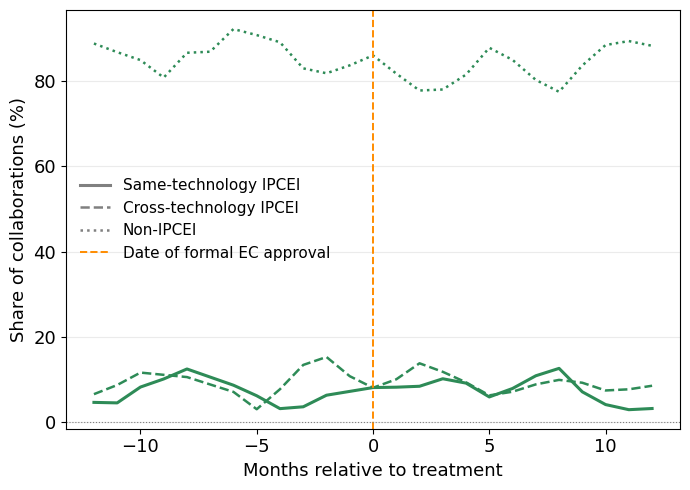

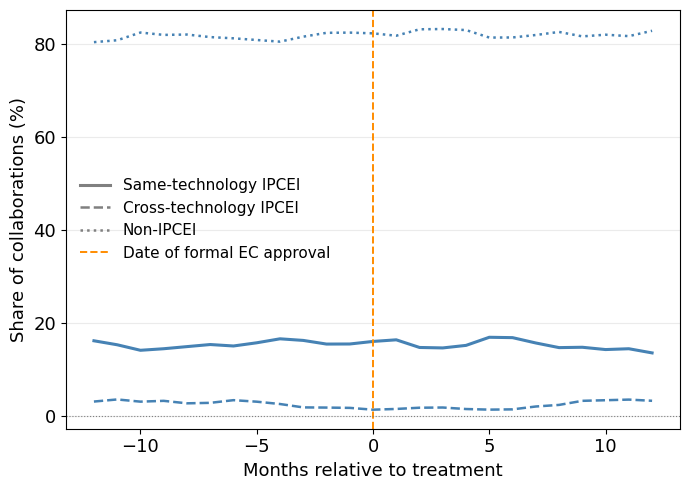

In [7]:
# ============================================================
# Collaboration composition over event time
# Shares by partner type (treated firms only)
# Comparable to pre-trends: same event-time logic, but composition not levels
# ============================================================

def build_partner_type_event_shares(firm_master_ipcei, partnership_master, window=12):
    fm = firm_master_ipcei.copy()
    fm["first_battery_date"]  = pd.to_datetime(fm["first_battery_date"],  errors="coerce")
    fm["first_hydrogen_date"] = pd.to_datetime(fm["first_hydrogen_date"], errors="coerce")

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])
    all_ipcei_firms = battery_firms | hydrogen_firms

    # focal firm × tech × treatment date
    treat_rows = []
    for _, row in fm.iterrows():
        firm = row["Linkedin_name"]
        if pd.notna(row["first_battery_date"]):
            treat_rows.append({
                "firm": firm,
                "tech": "Battery",
                "t0": row["first_battery_date"]
            })
        if pd.notna(row["first_hydrogen_date"]):
            treat_rows.append({
                "firm": firm,
                "tech": "Hydrogen",
                "t0": row["first_hydrogen_date"]
            })

    treat_df = pd.DataFrame(treat_rows)

    pm = partnership_master.copy()
    pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
    pm = pm.dropna(subset=["post_date", "collaboration_id"]).copy()

    # make endpoint-long so focal firm can be either source or target
    long = pd.concat([
        pm.rename(columns={"source": "firm", "target": "partner"})[
            ["firm", "partner", "collaboration_id", "post_date"]
        ],
        pm.rename(columns={"target": "firm", "source": "partner"})[
            ["firm", "partner", "collaboration_id", "post_date"]
        ],
    ], ignore_index=True)

    # keep only firms with treatment dates
    long = long.merge(treat_df, on="firm", how="inner")

    # event month relative to that firm's treatment date
    long["event_month"] = (
        (long["post_date"].dt.year - long["t0"].dt.year) * 12
        + (long["post_date"].dt.month - long["t0"].dt.month)
    )
    long = long[long["event_month"].between(-window, window)].copy()

    # classify partner type relative to focal firm's technology
    def classify_partner(row):
        partner = row["partner"]
        tech = row["tech"]

        if tech == "Battery":
            same_set = battery_firms
            other_set = hydrogen_firms
        else:
            same_set = hydrogen_firms
            other_set = battery_firms

        if partner in same_set:
            return "Same-technology IPCEI"
        elif partner in other_set:
            return "Cross-technology IPCEI"
        else:
            return "Non-IPCEI"

    long["partner_type"] = long.apply(classify_partner, axis=1)

    # one count per focal firm × event month × partner type × collaboration_id
    # avoids double-counting within the same category
    counts = (
        long.drop_duplicates(["firm", "tech", "event_month", "partner_type", "collaboration_id"])
            .groupby(["tech", "event_month", "partner_type"])["collaboration_id"]
            .nunique()
            .reset_index(name="n_collabs")
    )

    # total collaborations at each event month within technology
    totals = (
        counts.groupby(["tech", "event_month"])["n_collabs"]
              .sum()
              .reset_index(name="n_total")
    )

    counts = counts.merge(totals, on=["tech", "event_month"], how="left")
    counts["share"] = 100 * counts["n_collabs"] / counts["n_total"]

    return counts


def plot_partner_type_composition_event_time(firm_master_ipcei, partnership_master):
    WINDOW = 12
    SMOOTH = 3

    agg = build_partner_type_event_shares(
        firm_master_ipcei=firm_master_ipcei,
        partnership_master=partnership_master,
        window=WINDOW
    )

    line_styles = {
        "Same-technology IPCEI":  {"linestyle": "-",  "linewidth": 2.2},
        "Cross-technology IPCEI": {"linestyle": "--", "linewidth": 1.8},
        "Non-IPCEI":              {"linestyle": ":",  "linewidth": 1.8},
    }

    legend_handles = [
        plt.Line2D([0], [0], color="grey", **ls, label=ptype)
        for ptype, ls in line_styles.items()
    ] + [
        plt.Line2D([0], [0], color="darkorange",
                   linestyle="--", linewidth=1.4,
                   label="Date of formal EC approval")
    ]

    for tech, color, figname in [
        ("Battery",  COLORS["two"][1], "collaborations_intra_ipcei_battery_lineplot"),
        ("Hydrogen", COLORS["two"][0], "collaborations_intra_ipcei_hydrogen_lineplot"),
    ]:
        fig, ax = plt.subplots(figsize=(7, 5))
        sub = agg[agg["tech"] == tech].copy()

        for ptype, ls in line_styles.items():
            s = (
                sub[sub["partner_type"] == ptype]
                .sort_values("event_month")
                .set_index("event_month")["share"]
                .rolling(SMOOTH, center=True, min_periods=1)
                .mean()
            )
            ax.plot(s.index, s.values, color=color, **ls)

        ax.axvline(0, linestyle="--", color="darkorange",
                   linewidth=1.4)
        ax.axhline(0, linestyle=":", color="grey", linewidth=0.8)

        ax.set_xlabel("Months relative to treatment", fontsize=13)
        ax.set_ylabel("Share of collaborations (%)", fontsize=13)
        ax.tick_params(axis="both", labelsize=13)
        style_ax(ax)

        ax.legend(handles=legend_handles, frameon=False,
                  fontsize=11, loc="center left")

        plt.tight_layout()
        save_fig(fig, "results_descriptive", figname)
        plt.show()


plot_partner_type_composition_event_time(firm_master_ipcei, partnership_master)

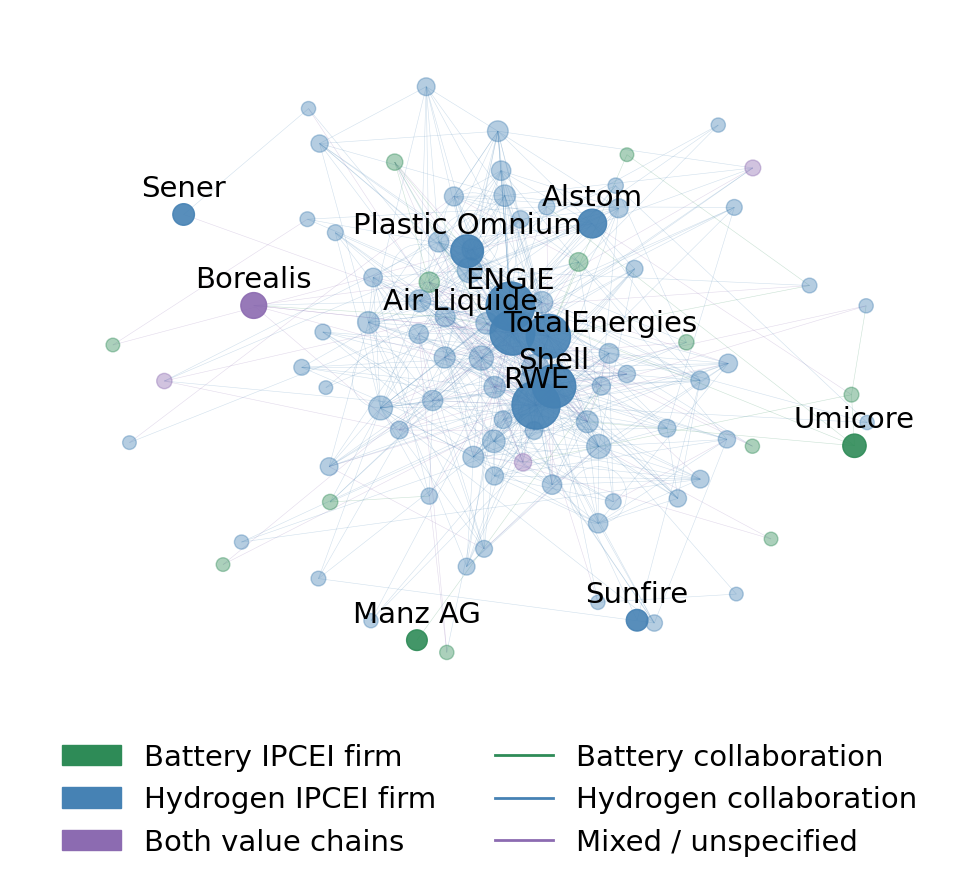

In [8]:
# ============================================================
# Collaboration composition pre-T
# Network plot
# ============================================================

def plot_intra_ipcei_network():
    import networkx as nx
    from matplotlib.lines import Line2D

    fm = firm_master_ipcei.copy()
    fm["first_battery_date"]  = pd.to_datetime(fm["first_battery_date"],  errors="coerce")
    fm["first_hydrogen_date"] = pd.to_datetime(fm["first_hydrogen_date"], errors="coerce")

    battery_firms  = set(fm.loc[fm["first_battery_date"].notna(),  "Linkedin_name"])
    hydrogen_firms = set(fm.loc[fm["first_hydrogen_date"].notna(), "Linkedin_name"])
    all_ipcei      = battery_firms | hydrogen_firms

    t0_lookup = {}
    for _, row in fm.iterrows():
        dates = []
        if pd.notna(row["first_battery_date"]):
            dates.append(row["first_battery_date"])
        if pd.notna(row["first_hydrogen_date"]):
            dates.append(row["first_hydrogen_date"])
        if dates:
            t0_lookup[row["Linkedin_name"]] = min(dates)

    pm = partnership_master.copy()
    pm["post_date"] = pd.to_datetime(pm["post_date"], errors="coerce")
    pm = pm.dropna(subset=["post_date"])

    edges = []
    for firm, t0 in t0_lookup.items():
        window_start = t0 - pd.DateOffset(months=12)
        sub = pm[
            (pm["source"] == firm) &
            (pm["target"].isin(all_ipcei)) &
            (pm["post_date"] >= window_start) &
            (pm["post_date"] < t0)
        ]
        for _, row in sub.iterrows():
            is_battery  = row.get("Battery",  0) == 1
            is_hydrogen = row.get("Hydrogen", 0) == 1
            if is_battery and not is_hydrogen:
                edge_tech = "Battery"
            elif is_hydrogen and not is_battery:
                edge_tech = "Hydrogen"
            else:
                edge_tech = "Mixed"
            edges.append((firm, row["target"], edge_tech))

    if not edges:
        print("No intra-IPCEI edges found in pre-approval window.")
        return

    edge_df = pd.DataFrame(edges, columns=["source", "target", "tech"])

    G_full = nx.Graph()
    for _, row in edge_df.iterrows():
        if G_full.has_edge(row["source"], row["target"]):
            G_full[row["source"]][row["target"]]["weight"] += 1
        else:
            G_full.add_edge(row["source"], row["target"],
                            weight=1, tech=row["tech"])

    nodes_to_keep = [n for n, d in G_full.degree() if d >= 2]
    G = G_full.subgraph(nodes_to_keep).copy()

    if len(G.nodes()) == 0:
        print("No nodes remain after filtering.")
        return

    deg = nx.degree_centrality(G)

    def node_color(n):
        in_b = n in battery_firms
        in_h = n in hydrogen_firms
        if in_b and in_h:   return "#8c6bb1"
        if in_b:            return COLORS["two"][1]
        if in_h:            return COLORS["two"][0]
        return "#cccccc"

    edge_color_map = {
        "Battery":  COLORS["two"][1],
        "Hydrogen": COLORS["two"][0],
        "Mixed":    "#8c6bb1",
    }

    name_lookup = (
        fm[["Linkedin_name", "name"]]
        .copy()
        .assign(
            Linkedin_name = lambda d: d["Linkedin_name"].astype(str).str.strip(),
            name          = lambda d: d["name"].astype(str).str.strip()
        )
        .dropna(subset=["name"])
        .query("name != '' and name != 'nan'")
        .drop_duplicates("Linkedin_name")
        .set_index("Linkedin_name")["name"]
    )

    N_CENTER = 4
    N_MIDDLE = 5
    N_EDGE   = 3

    all_nodes_sorted = sorted(deg.keys(), key=lambda n: deg[n], reverse=True)
    top_nodes    = all_nodes_sorted[:N_CENTER]
    bottom_nodes = all_nodes_sorted[-N_EDGE:]
    remaining    = all_nodes_sorted[N_CENTER:-N_EDGE]
    step         = max(1, len(remaining) // N_MIDDLE)
    middle_nodes = remaining[::step][:N_MIDDLE]
    label_nodes  = set(top_nodes) | set(middle_nodes) | set(bottom_nodes)

    labels = {
        n: name_lookup.get(n, n)[:18]
        for n in label_nodes
        if name_lookup.get(n, "") not in ("", n)
    }

    node_list        = list(G.nodes())
    labelled_nodes   = [n for n in node_list if n in label_nodes]
    unlabelled_nodes = [n for n in node_list if n not in label_nodes]

    edge_colors = [edge_color_map[G[u][v]["tech"]] for u, v in G.edges()]
    edge_widths = [0.5 + G[u][v]["weight"] * 0.5 for u, v in G.edges()]

    # ── Layout with correct tuple stretching ─────────────────
    raw_pos = nx.spring_layout(G, k=2.0, iterations=100, seed=42)

    xs = np.array([raw_pos[n][0] for n in raw_pos])
    ys = np.array([raw_pos[n][1] for n in raw_pos])
    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()
    SCALE = 2.2

    pos = {
        n: (
            (raw_pos[n][0] - x_min) / (x_max - x_min) * SCALE - SCALE / 2,
            (raw_pos[n][1] - y_min) / (y_max - y_min) * SCALE - SCALE / 2
        )
        for n in raw_pos
    }

    pos_labels = {k: (v[0], v[1] + 0.10) for k, v in pos.items()}

    # Manual label offsets
    reverse_lookup = {v: k for k, v in name_lookup.items()}
    label_offsets  = {
        "TotalEnergies": (0.15, -0.05),
        "Air Liquide":   (-0.15, 0.02),
    }
    for display_name, (dx, dy) in label_offsets.items():
        linkedin_key = reverse_lookup.get(display_name) or next(
            (k for k, v in name_lookup.items()
             if display_name.lower() in v.lower()), None
        )
        if linkedin_key and linkedin_key in pos_labels:
            x, y = pos_labels[linkedin_key]
            pos_labels[linkedin_key] = (x + dx, y + dy)

    # ── Draw ─────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 9))

    nx.draw_networkx_edges(G, pos, ax=ax,
                           edge_color=edge_colors,
                           width=0.4, alpha=0.25)

    nx.draw_networkx_nodes(G, pos, ax=ax,
                           nodelist=labelled_nodes,
                           node_color=[node_color(n) for n in labelled_nodes],
                           node_size=[200 + deg[n] * 2000 for n in labelled_nodes],
                           alpha=0.90)

    nx.draw_networkx_nodes(G, pos, ax=ax,
                           nodelist=unlabelled_nodes,
                           node_color=[node_color(n) for n in unlabelled_nodes],
                           node_size=[80 + deg[n] * 800 for n in unlabelled_nodes],
                           alpha=0.40)

    nx.draw_networkx_labels(G, pos_labels, labels=labels,
                            ax=ax, font_size=21)

    # Explicit axis limits to use full canvas
    ax.set_xlim(-SCALE / 2 - 0.3, SCALE / 2 + 0.3)
    ax.set_ylim(-SCALE / 2 - 0.3, SCALE / 2 + 0.3)
    ax.axis("off")

    legend_elements = [
        mpatches.Patch(color=COLORS["two"][1],  label="Battery IPCEI firm"),
        mpatches.Patch(color=COLORS["two"][0],  label="Hydrogen IPCEI firm"),
        mpatches.Patch(color="#8c6bb1",          label="Both value chains"),
        Line2D([0], [0], color=COLORS["two"][1], linewidth=2,
               label="Battery collaboration"),
        Line2D([0], [0], color=COLORS["two"][0], linewidth=2,
               label="Hydrogen collaboration"),
        Line2D([0], [0], color="#8c6bb1",         linewidth=2,
               label="Mixed / unspecified"),
    ]

    fig.legend(handles=legend_elements, loc="lower center", ncol=2,
               frameon=False, fontsize=21,
               bbox_to_anchor=(0.5, 0.01))

    ax.set_position([0.02, 0.18, 0.96, 0.80])
    save_fig(fig, "results_descriptive",
             "collaborations_intra_ipcei_preapproval_network", tight=False)
    plt.show()

plot_intra_ipcei_network()

In [12]:
# ============================================================
# Partner overlap between treated firms and matched controls
# Primary matched samples: Battery Spec 2 and Hydrogen Spec 2
# ============================================================

def compute_partner_overlap(cs_panel, partnership_master, tech_name,
                            start_date=None, end_date=None,
                            save_prefix=None):
    """
    Compute partner-set overlap between treated firms and their matched controls.

    Overlap metrics:
      - n_treated_partners
      - n_control_partners
      - n_shared_partners
      - jaccard_overlap = shared / union

    Notes:
      - Uses unique collaboration partners from partnership_master
      - Treats source/target symmetrically
      - If start_date/end_date are given, restricts collaborations to that window
    """

    # --------------------------------------------------------
    # 1) Reduce to one row per matched firm
    # --------------------------------------------------------
    matched = (
        cs_panel[["Linkedin_name", "is_treated", "is_control", "matched_to"]]
        .drop_duplicates()
        .copy()
    )

    # treated firm's own id is stored in matched_to in your saved panels
    treated_units = matched.loc[matched["is_treated"] == 1, ["Linkedin_name", "matched_to"]].copy()
    controls      = matched.loc[matched["is_control"] == 1, ["Linkedin_name", "matched_to"]].copy()

    # If treated rows have matched_to missing for some reason, fall back to own name
    treated_units["treated_id"] = treated_units["matched_to"].fillna(treated_units["Linkedin_name"])
    controls["treated_id"] = controls["matched_to"]

    # control → treated pair table
    pair_df = (
        controls.rename(columns={"Linkedin_name": "control_firm"})
        .merge(
            treated_units[["treated_id", "Linkedin_name"]].rename(columns={"Linkedin_name": "treated_firm"}),
            on="treated_id",
            how="left"
        )
        [["treated_id", "treated_firm", "control_firm"]]
        .dropna()
        .drop_duplicates()
        .copy()
    )

    # --------------------------------------------------------
    # 2) Build partner sets from collaboration data
    # --------------------------------------------------------
    p = partnership_master.copy()
    p["post_date"] = pd.to_datetime(p["post_date"], errors="coerce")

    if start_date is not None:
        p = p.loc[p["post_date"] >= pd.Timestamp(start_date)].copy()
    if end_date is not None:
        p = p.loc[p["post_date"] < pd.Timestamp(end_date)].copy()

    # make collaborations undirected at the firm level
    long = pd.concat([
        p.rename(columns={"source": "firm", "target": "partner"})[["firm", "partner", "collaboration_id"]],
        p.rename(columns={"target": "firm", "source": "partner"})[["firm", "partner", "collaboration_id"]],
    ], ignore_index=True)

    long = long.dropna(subset=["firm", "partner"]).copy()

    partner_sets = (
        long.groupby("firm")["partner"]
        .agg(lambda s: set(pd.Series(s).dropna().astype(str)))
        .to_dict()
    )

    # --------------------------------------------------------
    # 3) Overlap metrics for each treated-control pair
    # --------------------------------------------------------
    rows = []
    for _, row in pair_df.iterrows():
        treated_firm = row["treated_firm"]
        control_firm = row["control_firm"]

        treated_partners = partner_sets.get(treated_firm, set())
        control_partners = partner_sets.get(control_firm, set())

        shared = treated_partners & control_partners
        union  = treated_partners | control_partners

        rows.append({
            "treated_firm": treated_firm,
            "control_firm": control_firm,
            "n_treated_partners": len(treated_partners),
            "n_control_partners": len(control_partners),
            "n_shared_partners": len(shared),
            "jaccard_overlap": len(shared) / len(union) if len(union) > 0 else np.nan,
            "shared_partner_examples": ", ".join(sorted(list(shared))[:10]) if len(shared) > 0 else ""
        })

    overlap_df = pd.DataFrame(rows)

    # --------------------------------------------------------
    # 4) Summary printout
    # --------------------------------------------------------
    print("\n" + "=" * 70)
    print(f"{tech_name.upper()} — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS")
    print("=" * 70)

    if overlap_df.empty:
        print("No treated-control pairs found.")
        return overlap_df

    print(f"Matched treated-control pairs: {len(overlap_df)}")
    print(f"Pairs with any shared partners: {(overlap_df['n_shared_partners'] > 0).sum()} "
          f"({100 * (overlap_df['n_shared_partners'] > 0).mean():.1f}%)")
    print(f"Mean shared partners: {overlap_df['n_shared_partners'].mean():.2f}")
    print(f"Median shared partners: {overlap_df['n_shared_partners'].median():.2f}")
    print(f"Mean Jaccard overlap: {overlap_df['jaccard_overlap'].mean():.4f}")
    print(f"Median Jaccard overlap: {overlap_df['jaccard_overlap'].median():.4f}")

    print("\nTop 10 pairs by Jaccard overlap:")
    display(
        overlap_df.sort_values(
            ["jaccard_overlap", "n_shared_partners"],
            ascending=[False, False]
        ).head(10)
    )

    # --------------------------------------------------------
    # 5) Save outputs (optional)
    # --------------------------------------------------------
    if save_prefix is not None:
        out_path = results_path("tables", "main", f"{save_prefix}_partner_overlap_pairs.csv")
        out_path.parent.mkdir(parents=True, exist_ok=True)
        overlap_df.to_csv(out_path, index=False)
        print(f"\nSaved pair-level overlap table to: {out_path}")

        summary_df = pd.DataFrame([{
            "technology": tech_name,
            "n_pairs": len(overlap_df),
            "share_with_any_overlap_pct": 100 * (overlap_df["n_shared_partners"] > 0).mean(),
            "mean_shared_partners": overlap_df["n_shared_partners"].mean(),
            "median_shared_partners": overlap_df["n_shared_partners"].median(),
            "mean_jaccard_overlap": overlap_df["jaccard_overlap"].mean(),
            "median_jaccard_overlap": overlap_df["jaccard_overlap"].median(),
        }])

        summary_path = results_path("tables", "main", f"{save_prefix}_partner_overlap_summary.csv")
        summary_df.to_csv(summary_path, index=False)
        print(f"Saved summary overlap table to: {summary_path}")

    return overlap_df


# ============================================================
# Run for primary matched samples
# ============================================================

battery_overlap = compute_partner_overlap(
    battery_cs,
    partnership_master,
    tech_name="Battery",
    start_date="2020-01-01",   # optional; remove if you want full sample
    end_date="2026-01-01",
    save_prefix="battery_spec2"
)

hydrogen_overlap = compute_partner_overlap(
    hydrogen_cs,
    partnership_master,
    tech_name="Hydrogen",
    start_date="2020-01-01",
    end_date="2026-01-01",
    save_prefix="hydrogen_spec2"
)


BATTERY — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS
Matched treated-control pairs: 196
Pairs with any shared partners: 67 (34.2%)
Mean shared partners: 3.73
Median shared partners: 0.00
Mean Jaccard overlap: 0.0056
Median Jaccard overlap: 0.0000

Top 10 pairs by Jaccard overlap:


,treated_firm,control_firm,n_treated_partners,n_control_partners,n_shared_partners,jaccard_overlap,shared_partner_examples
92,avl,irizar-e-mobility,853,310,118,0.112919,"-transdev, Datik, POLIS network, alstom, applu..."
99,inobat1,korepower,210,83,12,0.042705,"2633, EVE Energy Co.,Ltd., abb, batteriesnews,..."
40,borealis,covestro,258,384,26,0.042208,"2633, abb, adnoc, adnocgroup, airliquide, basf..."
82,borealis,heidelbergmaterials,258,579,31,0.038462,"2633, abb, ademe, airliquide, basf, bp, cinea-..."
113,valmet-automotive,marecon-management-&-research,82,31,4,0.036697,"coventry-university, ika-rwth, university-of-s..."
39,arkema,corvus-energy-ltd.,589,808,47,0.034815,"AIT Austrian Institute of Technology, NORCE Re..."
15,borealis,arcelormittal,258,974,40,0.033557,"2633, abb, ademe, airliquide, basf, bp, cinea-..."
111,borealis,manenergysolutions,258,1003,36,0.029388,"2633, abb, ademe, adnocgroup, airliquide, axpo..."
145,fpt-industrial,saint-gobain,251,463,20,0.028818,"AIT Austrian Institute of Technology, airliqui..."
4,arkema,air-france,589,226,22,0.027743,"a-roports-de-lyon, airbusgroup, axens, bioecon..."



Saved pair-level overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/main/battery_spec2_partner_overlap_pairs.csv
Saved summary overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/main/battery_spec2_partner_overlap_summary.csv

HYDROGEN — PARTNER OVERLAP BETWEEN TREATED FIRMS AND MATCHED CONTROLS
Matched treated-control pairs: 271
Pairs with any shared partners: 152 (56.1%)
Mean shared partners: 12.45
Median shared partners: 1.00
Mean Jaccard overlap: 0.0114
Median Jaccard overlap: 0.0043

Top 10 pairs by Jaccard overlap:


,treated_firm,control_firm,n_treated_partners,n_control_partners,n_shared_partners,jaccard_overlap,shared_partner_examples
230,enbw,sse-renewables,1123,965,202,0.107105,"50hertz-transmission-gmbh, H2sea - Offshore Hy..."
243,vngag,th-ga-aktiengesellschaft,310,170,43,0.098398,"00-mitnetz-gas, Currenta, Federal Ministry for..."
249,mcphy,valorem_2,685,560,102,0.089239,"-transdev, 34956182, 3e-hycalor-hydrogene, 746..."
10,repsol,acciona,1193,1178,173,0.078708,"ARIEMA, Cemex, Centro Nacional de Energías Ren..."
86,enbw,edp-renov-veis,1123,876,137,0.073577,"Edison, HitachiEnergy, Moeve, abb, abo-wind, a..."
120,enbw,gasunie,1123,1073,134,0.064985,"2633, 50hertz-transmission-gmbh, DESFA, EUROPI..."
32,avl,ballard-power-systems,853,1136,121,0.064775,"airbusgroup, airliquide, alstom, arrivagroup, ..."
251,symbiofcell,vdl-groep,321,650,58,0.063527,"-transdev, TRANSPOLIS, airliquide, alstom, avl..."
18,lhyfe,alfa-laval,1123,610,102,0.062538,"2030sekretariatet, 2633, HOPE: Hydrogen Offsho..."
229,borealis,ssab,258,260,28,0.057143,"abb, afry, airliquide, basf, business-finland,..."



Saved pair-level overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/main/hydrogen_spec2_partner_overlap_pairs.csv
Saved summary overlap table to: /Users/go82gax/Documents/Projekte/IPCEI/Analyse/PythonProject/ipcei-spillovers/results/tables/main/hydrogen_spec2_partner_overlap_summary.csv
